# Project 8: Inverse problems with multiple valid solutions

**MAC 312: Foundations of Data Science** · group project notebook (6 members)

## The problem in one paragraph
Someone draws a secret number $t$ uniformly from $[-a, a]$, squares it, adds Gaussian noise and shows us
$x = t^2 + \epsilon$, $\epsilon \sim \mathcal N(0, \sigma^2)$. We want to recover $t$ from $x$.
Squaring throws away the sign, so an observation like $x \approx 1$ is explained equally well by
$t \approx +1$ and $t \approx -1$. **The inverse problem has more than one valid answer.** A model that
outputs a single number cannot represent that. A model that outputs a *probability distribution*
over $t$ can.

## Central research question
> Does a conventional point predictor (MSE network) fail on this non-unique inverse problem, can a
> mixture density network (MDN) recover the full multi-branch conditional density $p(t\mid x)$, and
> **how reliably does it recover both inverse branches as the prior becomes imbalanced and the
> observation noise increases?**

## Map from notebook sections to the assignment

| Notebook section | Assignment part |
|---|---|
| §3 Conditional density by quadrature, input regions | **Part 1** |
| §4 Squared-error network, conditional mean, "between the branches" | **Part 2** |
| §5 Mixture density network (positivity, normalisation, stable likelihood) | **Part 3** |
| §6 Held-out NLL vs single Gaussian, density/branch comparison, samples, forward residuals | **Part 4** |
| §7 Asymmetric prior, missing branches, sensitivity to $M$, initialisation and variance floor; why MSE cannot assess this | **Part 5** |
| §8 Extension: branch-probability error, branch-recovery score, Wasserstein-1, noise robustness | Our additional contribution |
| §9 Summary and conclusions | – |

**How the code is organised.** Reusable functions live in the small package `src/p8/` (data,
reference posterior, models, training, evaluation, plotting). This notebook imports them and holds
all the maths, experiments, plots and interpretation. Every number and figure below is produced by
the code in this notebook. Nothing is typed in by hand.

## 1. Setup: imports, configuration, seeds, device

In [1]:
import sys, json, platform, warnings
from dataclasses import replace
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import torch
from scipy import integrate
from scipy.stats import norm

from p8.config import DataConfig, TrainConfig, MDNConfig, CODE_VERSION
from p8.data import set_seed, make_splits
from p8 import reference as R
from p8 import evaluate as E
from p8.training import DEVICE, train_mse_model, train_mae_model, train_single_gaussian_model, train_mdn
from p8.experiments import T_GRID, N_EVAL, get_context, get_model, run_mdn_setting, run_sweep, mean_sd_table
from p8.plotting import COLORS, set_style, savefig, plot_history

set_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

# ---- selected experimental settings (our choices; the assignment only requires a, sigma > 0) ----
BASE_DATA = DataConfig()          # a=2, sigma=0.15, q=0.5, 10k/2k/2k split, data_seed=2026
TRAIN     = TrainConfig()         # 3x64 tanh MLP, Adam 2e-3, batch 256, early stopping (patience 40)
BASE_MDN  = MDNConfig()           # M=3 components, variance floor 1e-4, default init
A, SIGMA  = BASE_DATA.a, BASE_DATA.sigma
SEEDS     = [0, 1, 2, 3, 4]       # model-initialisation seeds for every repeated experiment
M_LIST    = [1, 2, 3, 5]
Q_LIST    = [0.5, 0.7, 0.9, 0.97] # P(t > 0) under the prior
FLOORS    = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
SIGMAS    = [0.05, 0.15, 0.30, 0.50]
USE_CACHE = True                  # reuse a trained run only if *every* setting is identical (hashed key)

set_seed(0)
RESULTS = Path("artifacts/results"); RESULTS.mkdir(parents=True, exist_ok=True)
CKPT = Path("artifacts/checkpoints"); CKPT.mkdir(parents=True, exist_ok=True)

settings = dict(data=BASE_DATA.to_dict(), train=TRAIN.to_dict(), mdn=BASE_MDN.to_dict(), seeds=SEEDS,
                M_list=M_LIST, q_list=Q_LIST, var_floors=FLOORS, sigmas=SIGMAS, t_grid=[-2, 2, len(T_GRID)],
                n_eval=N_EVAL, code_version=CODE_VERSION)
(RESULTS / "settings.json").write_text(json.dumps(settings, indent=2))

print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"torch {torch.__version__} | pandas {pd.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Python 3.13.5 | numpy 2.5.4 | scipy 1.18.1 | torch 2.14.1+cu126 | pandas 3.1.1
device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU


### Selected settings and why we chose them

| Setting | Value | Reason |
|---|---|---|
| Prior support $a$ | 2.0 | Gives $x$ roughly in $[0, 4]$, enough room for well-separated branches $\pm\sqrt x$. |
| Noise $\sigma$ | 0.15 (baseline) | Small next to $a^2 = 4$, so the branches are clearly separated for most $x$, but large enough that the merged region near $x=0$ is visible. Noise is in units of $x$ (it is added to $t^2$). |
| Data sizes | 10 000 train / 2 000 validation / 2 000 test | i.i.d. draws from one generator seeded with `data_seed=2026`. Large enough for stable training of a small net. |
| Network | 3 hidden layers × 64 units, tanh | Small and easy to explain. The input is 1-D. |
| Optimiser | Adam, lr $2\times10^{-3}$, batch 256, gradient clipping at norm 5 | Standard and stable. Clipping guards against rare NLL spikes. |
| Stopping rule | max 400 epochs, early stopping with patience 40 on **validation** loss, best-validation weights restored | The test set is never used for training or tuning. |
| MDN components | $M=3$ baseline. We also compare $M\in\{1,2,3,5\}$ | Two branches plus one spare component for the merged and boundary regions. Validated in §6. |
| Variance floor $v_{\min}$ | $10^{-4}$ (a **variance**, i.e. std floor 0.01) | Below every posterior variance in our regions, the smallest being $(\sigma/2a)^2\approx 1.4\times10^{-3}$ at the boundary for $\sigma=0.15$. It prevents a component from collapsing to zero width. |
| Seeds | 5 model-initialisation seeds (0–4) | The dataset is held fixed so the spread across seeds isolates initialisation effects. |
| Imbalance levels $q=P(t>0)$ | 0.5, 0.7, 0.9 (suggested) plus **0.97** (our extra stress test) | 0.97 checks whether a very rare branch gets lost. |
| Noise levels | $\sigma \in \{0.05, 0.15, 0.30, 0.50\}$ | From sharply separated to heavily blurred branches. |

Seeds for Python, NumPy and PyTorch are fixed via `set_seed`. All settings are written to
`artifacts/results/settings.json`.

## 2. The generative model

$$ t \sim p_q(t), \qquad x = t^2 + \epsilon, \qquad \epsilon \sim \mathcal N(0,\sigma^2). $$

The baseline prior is the assignment's $\mathrm{Unif}[-a,a]$. For Part 5 we use the piecewise-uniform prior

$$ p_q(t) = \begin{cases} (1-q)/a, & -a \le t < 0 \\ q/a, & 0 \le t \le a \end{cases}, \qquad q = P(t>0), $$

which integrates to one and equals $\mathrm{Unif}[-a,a]$ when $q=0.5$. We sample it by drawing the sign
($+$ with probability $q$) and then $|t| \sim \mathrm{Unif}[0,a]$ (`p8.data.sample_prior`).

q = 0.5 (baseline): train fraction t>0 = 0.508, x range = [-0.45, 4.38]
q = 0.9: train fraction t>0 = 0.905, x range = [-0.45, 4.38]


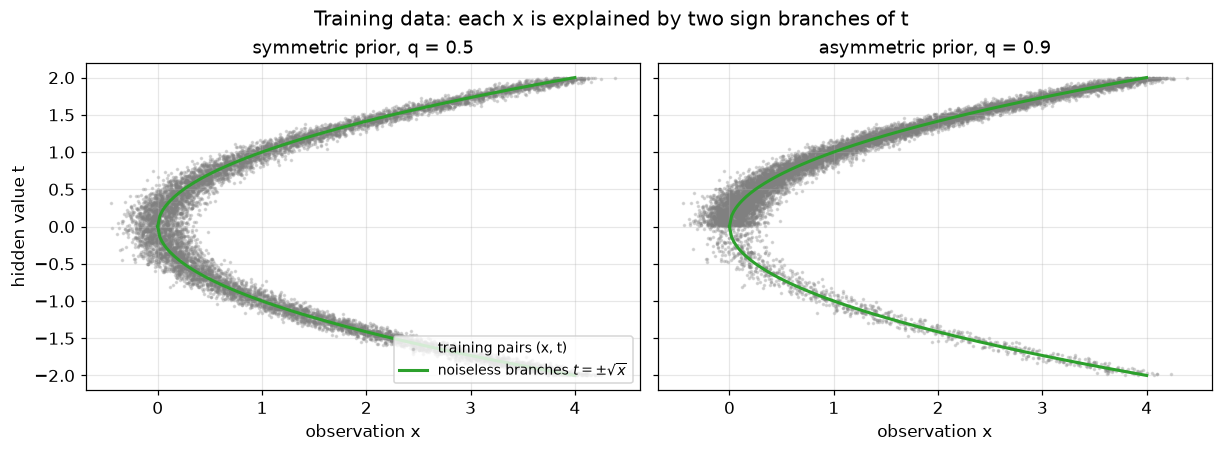

In [2]:
base = get_context(BASE_DATA)               # splits + reference quantities for the baseline data
asym9 = get_context(replace(BASE_DATA, q=0.9))
for name, ctx in [("q = 0.5 (baseline)", base), ("q = 0.9", asym9)]:
    xtr, ttr = ctx.splits["train"]
    print(f"{name}: train fraction t>0 = {np.mean(ttr > 0):.3f}, x range = [{xtr.min():.2f}, {xtr.max():.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, ctx) in zip(axes, [("symmetric prior, q = 0.5", base), ("asymmetric prior, q = 0.9", asym9)]):
    xtr, ttr = ctx.splits["train"]
    ax.scatter(xtr, ttr, s=2, alpha=0.25, color="grey", label="training pairs (x, t)")
    xs = np.linspace(0, A**2, 200)
    ax.plot(xs, np.sqrt(xs), color=COLORS["branch"], lw=2, label=r"noiseless branches $t=\pm\sqrt{x}$")
    ax.plot(xs, -np.sqrt(xs), color=COLORS["branch"], lw=2)
    ax.set(xlabel="observation x", title=name)
axes[0].set_ylabel("hidden value t"); axes[0].legend(loc="lower right")
fig.suptitle("Training data: each x is explained by two sign branches of t")
savefig(fig, "02_data"); plt.show()

For every positive $x$ the data shows two "arms" at $t\approx\pm\sqrt x$. With $q=0.9$ the lower arm
is much sparser, but it is still there.

## 3. Part 1: conditional density by one-dimensional quadrature

### 3.1 Derivation
By Bayes' rule $p(t\mid x) \propto p(x\mid t)\,p(t)$, with

$$ p(x\mid t) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Big[-\frac{(x-t^2)^2}{2\sigma^2}\Big], \qquad p(t) = \frac{1}{2a}\,\mathbb 1[-a\le t\le a]. $$

The factors $1/\sqrt{2\pi\sigma^2}$ and $1/(2a)$ do not depend on $t$, so they cancel when we normalise:

$$ p(t\mid x) = \frac{\exp\!\big[-\frac{(x-t^2)^2}{2\sigma^2}\big]}{Z(x)}\,\mathbb 1[-a\le t\le a],
\qquad Z(x) = \int_{-a}^{a}\exp\!\Big[-\frac{(x-u^2)^2}{2\sigma^2}\Big]du. $$

$Z(x)$ has no elementary closed form, so we compute it with `scipy.integrate.quad`. For the
asymmetric prior the integrand gets an extra weight $w(u)=2q$ for $u\ge0$ and $2(1-q)$ for $u<0$.

**Numerical details** (`p8/reference.py`):
* We subtract the maximum log-likelihood $\max_t[-(x-t^2)^2/2\sigma^2]$, attained at $t^2=\mathrm{clip}(x,0,a^2)$, before exponentiating. This avoids underflow for very negative or very large $x$.
* We integrate $[-a,0]$ and $[0,a]$ separately, because the asymmetric prior jumps at 0, and we pass the peak location $\pm\sqrt{x}$ to `quad` so it never steps over a narrow mode.

### 3.2 Where are the modes? Input regions with distinct branches
$\frac{d}{dt}\log p(t\mid x) = \frac{2t(x-t^2)}{\sigma^2}$ is zero at $t=0$ and at $t^2=x$. Hence:

* **$x\le 0$ (no real inverse):** a single mode at $t=0$.
* **$0<x\le a^2$:** modes exactly at $t=\pm\sqrt x$, and $t=0$ becomes a local *minimum* (since $\tfrac{d^2}{dt^2}\log p\,|_{t=0} = 2x/\sigma^2 > 0$). How visible the two modes are depends on the dip between them: $p(0\mid x)/p(\sqrt x\mid x) = e^{-x^2/2\sigma^2}$. For $x \lesssim 2\sigma$ the dip ratio is above $e^{-2}\approx0.14$ and the two branches **merge** into one broad bump. For $x\ge 2\sigma$ they are **distinct**.
* **$x>a^2$ (beyond support):** the prior cuts off at $\pm a$, so the modes are pinned to the boundary $t=\pm a$, **not** at $\pm\sqrt{x}$.

Near each mode $\frac{d^2}{dt^2}\log p = -4x/\sigma^2$, so the local posterior standard deviation is
$\sigma/(2\sqrt x)$. We reuse this width later to define branch neighbourhoods.

In [3]:
# ---- normalisation, symmetry and branch-probability checks ----
x_checks = [-0.4, 0.0, 0.1, 0.3, 1.0, 2.5, 3.9, 4.6]
rows = []
for q in [0.5, 0.9]:
    for x in x_checks:
        logZ = R.log_normalizing_constant(x, A, SIGMA, q)
        dens_fn = lambda u: np.exp(R.log_unnormalized_posterior(u, x, A, SIGMA, q) - logZ)
        pk = float(np.sqrt(np.clip(x, 0, A**2)))
        pts = sorted({0.0, pk, -pk})
        integral = integrate.quad(dens_fn, -A, A, points=pts, limit=200, epsabs=1e-12)[0]
        dens = R.reference_density_grid([x], T_GRID, A, SIGMA, q)[0]
        rows.append(dict(q=q, x=x, region=R.classify_region(x, A, SIGMA), log_Z=logZ,
                         integral_quad=integral, integral_grid=np.trapezoid(dens, T_GRID),
                         P_pos=R.reference_branch_probability(x, A, SIGMA, q),
                         E_t_given_x=R.reference_mean(x, A, SIGMA, q),
                         max_sym_err=np.abs(dens - dens[::-1]).max() if q == 0.5 else np.nan))
checks = pd.DataFrame(rows)
display(checks)
assert np.allclose(checks.integral_quad, 1, atol=1e-6)
assert np.allclose(checks.P_pos, checks.q, atol=1e-8)
assert np.allclose(checks.query("q == 0.5").E_t_given_x, 0, atol=1e-8)
print("All checks passed: densities integrate to 1, P(t>0|x) = q, and E[t|x] = 0 under the symmetric prior.")

,q,x,region,log_Z,integral_quad,integral_grid,P_pos,E_t_given_x,max_sym_err
0,0.5,-0.4,no real inverse,-4.4650,1.0,1.0000,0.5,0.0000,4.4409e-15
1,0.5,0.0,no real inverse,-0.1804,1.0,1.0000,0.5,0.0000,9.9920e-16
2,0.5,0.1,merged,-0.0112,1.0,1.0000,0.5,0.0000,1.2212e-15
3,0.5,0.3,two branches,-0.2577,1.0,1.0000,0.5,0.0000,1.7764e-15
4,0.5,1.0,two branches,-0.9693,1.0,1.0000,0.5,0.0000,1.1768e-14
5,0.5,2.5,two branches,-1.4350,1.0,1.0000,0.5,0.0000,1.5543e-14
6,0.5,3.9,two branches,-1.9411,1.0,1.0000,0.5,0.0000,2.5757e-14
7,0.5,4.6,beyond support,-12.0272,1.0,1.0010,0.5,0.0000,1.1227e-12
8,0.9,-0.4,no real inverse,-4.4650,1.0,1.0020,0.9,0.1001,NaN
9,0.9,0.0,no real inverse,-0.1804,1.0,1.0010,0.9,0.1801,NaN


All checks passed: densities integrate to 1, P(t>0|x) = q, and E[t|x] = 0 under the symmetric prior.


**Reading the table.**
* `integral_quad` is the integral of the normalised density by quadrature, and it is 1 to within $10^{-6}$ everywhere.
* `integral_grid` is the same integral by the trapezoid rule on our common grid (4001 points, spacing 0.001). It is slightly off only where the density has a kink the grid cannot resolve: the prior jump at $t=0$ when $q\ne0.5$, or the sharp boundary peak for $x>a^2$. This is why all our grid-based densities are normalised with the quadrature $Z(x)$, not with the grid sum.
* `P_pos` equals $q$ for every $x$. This must hold: the likelihood depends only on $t^2$, so it treats $\pm t$ identically and the posterior sign probability equals the prior one. Under the symmetric prior, $p(t\mid x)=p(-t\mid x)$ (`max_sym_err` = 0) and $E[t\mid x]=0$.
* A 50:50 sign probability on its own does **not** mean there are two modes. At $x=-0.4$ the split is also 50:50, but the density is a single bump at 0.

In [4]:
# ---- quadrature accuracy: tolerance and an independent fine-grid check ----
rows = []
fine = np.linspace(-A, A, 400_001)
for x in [0.1, 1.0, 3.9, 4.6]:
    tight = R.log_normalizing_constant(x, A, SIGMA, epsabs=1e-12, epsrel=1e-10)
    loose = R.log_normalizing_constant(x, A, SIGMA, epsabs=1e-6, epsrel=1e-6)
    trap = np.log(np.trapezoid(np.exp(R.log_unnormalized_posterior(fine, x, A, SIGMA)), fine))
    rows.append(dict(x=x, logZ_tight=tight, logZ_loose_minus_tight=loose - tight, logZ_finegrid_minus_tight=trap - tight))
display(pd.DataFrame(rows))

,x,logZ_tight,logZ_loose_minus_tight,logZ_finegrid_minus_tight
0,0.1,-0.0112,0.0000e+00,-1.1102e-16
1,1.0,-0.9693,0.0000e+00,0.0000e+00
2,3.9,-1.9411,1.9984e-15,-1.6528e-09
3,4.6,-12.0272,0.0000e+00,9.9735e-08


Loosening the quadrature tolerance by four orders of magnitude, or replacing quadrature by a
400 001-point trapezoid rule, changes $\log Z$ by a negligible amount. The reference is accurate
enough to serve as ground truth.

In [5]:
# ---- mode locations: numerical (grid local maxima) vs the analytic result ----
def grid_modes(dens, grid, rel=1e-3):
    # local maxima of a density on a grid (endpoints included), ignoring tiny bumps
    d = dens
    left = np.r_[-np.inf, d[:-1]]; right = np.r_[d[1:], -np.inf]
    idx = np.where((d > left) & (d >= right) & (d > rel * d.max()))[0]
    return grid[idx]

rows = []
for x in x_checks:
    d = R.reference_density_grid([x], T_GRID, A, SIGMA)[0]
    rows.append(dict(x=x, region=R.classify_region(x, A, SIGMA), numerical_modes=np.round(grid_modes(d, T_GRID), 3),
                     analytic_modes=np.round(R.reference_modes(x, A, SIGMA), 3), dip_ratio=R.dip_ratio(x, SIGMA)))
display(pd.DataFrame(rows))

,x,region,numerical_modes,analytic_modes,dip_ratio
0,-0.4,no real inverse,[0.0],[0.0],1.0000e+00
1,0.0,no real inverse,[0.0],[0.0],1.0000e+00
2,0.1,merged,"[-0.316, 0.316]","[-0.316, 0.316]",8.0074e-01
3,0.3,two branches,"[-0.548, 0.548]","[-0.548, 0.548]",1.3534e-01
4,1.0,two branches,"[-1.0, 1.0]","[-1.0, 1.0]",2.2336e-10
5,2.5,two branches,"[-1.581, 1.581]","[-1.581, 1.581]",4.8009e-61
6,3.9,two branches,"[-1.975, 1.975]","[-1.975, 1.975]",1.6161e-147
7,4.6,beyond support,"[-2.0, 2.0]","[-2.0, 2.0]",6.0965e-205


The numerically detected modes agree with the analysis: one mode at $0$ for $x\le0$, modes at
$\pm\sqrt{x}$ inside the support, and modes pinned at $\pm a=\pm2$ for $x=4.6>a^2$. At $x=0.1$ there are
technically two modes, but the dip ratio is about 0.8, so they are barely distinguishable (the
**merged** region).

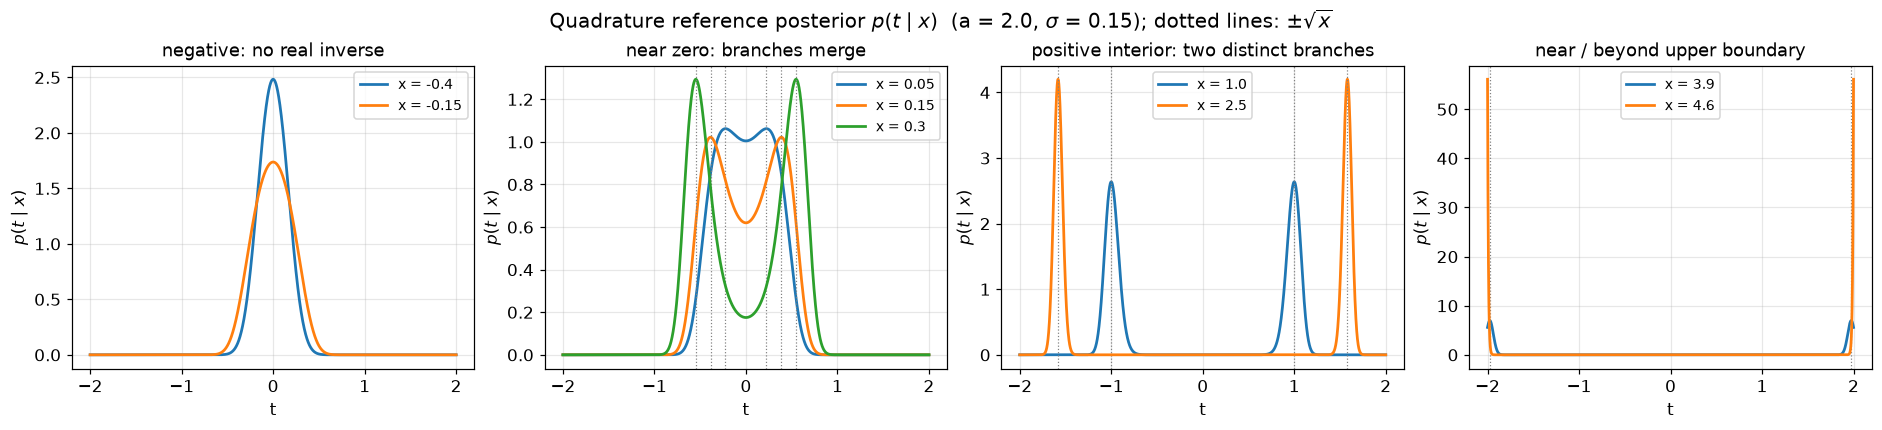

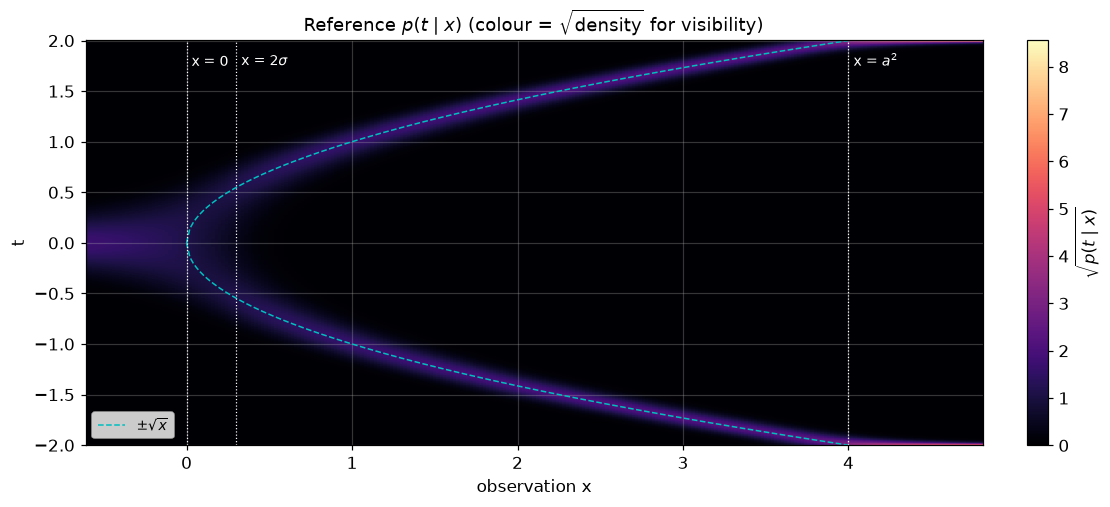

In [6]:
# ---- reference densities for representative observations ----
panels = [("negative: no real inverse", [-0.4, -0.15]),
          ("near zero: branches merge", [0.05, 0.15, 0.3]),
          ("positive interior: two distinct branches", [1.0, 2.5]),
          ("near / beyond upper boundary", [3.9, 4.6])]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=False)
for ax, (title, xs) in zip(axes, panels):
    for x in xs:
        ax.plot(T_GRID, R.reference_density_grid([x], T_GRID, A, SIGMA)[0], lw=1.8, label=f"x = {x}")
        if 0 < x <= A**2:
            for s in (-1, 1):
                ax.axvline(s * np.sqrt(x), color="grey", ls=":", lw=0.8)
    ax.set(title=title, xlabel="t", ylabel=r"$p(t \mid x)$")
    ax.legend()
fig.suptitle(fr"Quadrature reference posterior $p(t\mid x)$  (a = {A}, $\sigma$ = {SIGMA}); dotted lines: $\pm\sqrt{{x}}$")
savefig(fig, "03_reference_densities"); plt.show()

# ---- the whole conditional density as a heat map ----
x_hm = np.linspace(-0.6, 4.8, 271)
t_hm = T_GRID[::4]
dens_hm = R.reference_density_grid(x_hm, t_hm, A, SIGMA)
fig, ax = plt.subplots(figsize=(10, 4.5))
pcm = ax.pcolormesh(x_hm, t_hm, np.sqrt(dens_hm.T), shading="auto", cmap="magma")
xs = np.linspace(0, A**2, 200)
ax.plot(xs, np.sqrt(xs), "c--", lw=1, label=r"$\pm\sqrt{x}$"); ax.plot(xs, -np.sqrt(xs), "c--", lw=1)
for xv, lab in [(0, "x = 0"), (2 * SIGMA, r"x = 2$\sigma$"), (A**2, r"x = $a^2$")]:
    ax.axvline(xv, color="w", lw=0.8, ls=":")
    ax.text(xv + 0.03, 1.75, lab, color="w", fontsize=9)
ax.set(xlabel="observation x", ylabel="t", title=r"Reference $p(t\mid x)$ (colour = $\sqrt{\mathrm{density}}$ for visibility)")
fig.colorbar(pcm, ax=ax, label=r"$\sqrt{p(t\mid x)}$"); ax.legend(loc="lower left")
savefig(fig, "03_reference_heatmap"); plt.show()

**Input regions (baseline $a=2$, $\sigma=0.15$):**

| Region | $x$ range | Posterior shape |
|---|---|---|
| No real inverse | $x\le 0$ | One mode at $t=0$, getting narrower as $x$ becomes more negative |
| Merged | $0 < x < 2\sigma = 0.3$ | Two modes exist mathematically but form one broad bump |
| **Two distinct branches** | $0.3 \le x \le 4$ | Two well-separated modes at $\pm\sqrt{x}$ |
| Beyond support | $x > 4$ | Modes pinned at $t=\pm2$ by the prior support |

The heat map shows the whole picture: a single ridge at $t=0$ for negative $x$ that splits into the
two branches $\pm\sqrt{x}$ and then stops at $\pm a$.

## 4. Part 2: squared-error (MSE) neural network

We train $f_\theta(x)$ by minimising $\mathcal L_{\rm MSE}(\theta)=\frac1N\sum_i (f_\theta(x_i)-t_i)^2$.

**What population quantity does it estimate?** For any function $f$,

$$ \mathbb E\big[(f(x)-t)^2\big] = \mathbb E\big[(f(x)-\mathbb E[t\mid x])^2\big] + \mathbb E\big[\mathrm{Var}(t\mid x)\big], $$

and the second term does not depend on $f$. So the population minimiser is the **conditional mean**
$f^*(x)=\mathbb E[t\mid x]$. With the symmetric prior, $\mathbb E[t\mid x]=0$ for *every* $x$, so the ideal
MSE network outputs 0 everywhere. That is not a valid inverse for any $x>0$, since $0^2 \ne x$.
The network is doing exactly what its loss asks. The problem is that one number cannot represent two
answers. Below we compare the trained network with the quadrature value of $\mathbb E[t\mid x]$,
for the symmetric prior and for the $q=0.9$ prior.

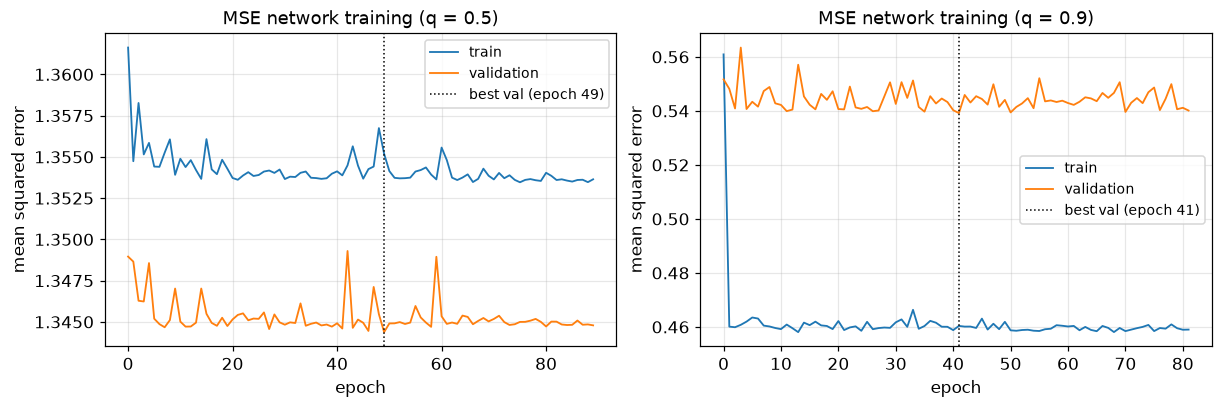

q = 0.5: best val MSE 1.3444 at epoch 49 (90 epochs run, early stopping)
q = 0.9: best val MSE 0.5392 at epoch 41 (82 epochs run, early stopping)


In [7]:
mse_models = {}
for name, ctx in [("q = 0.5", base), ("q = 0.9", asym9)]:
    model, hist, _ = train_mse_model(ctx.dcfg, TRAIN, seed=0, splits=ctx.splits, use_cache=USE_CACHE, verbose=True)
    mse_models[name] = (model, hist, ctx)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (name, (model, hist, ctx)) in zip(axes, mse_models.items()):
    plot_history(ax, hist, f"MSE network training ({name})", "mean squared error")
savefig(fig, "04_mse_training"); plt.show()
for name, (model, hist, ctx) in mse_models.items():
    print(f"{name}: best val MSE {hist['best_val']:.4f} at epoch {hist['best_epoch']} ({hist['epochs_run']} epochs run, early stopping)")

The loss drops to its final level within the first epoch and then just fluctuates (note the very
narrow y-axis ranges). There is no upward drift in the validation loss, so there is no sign of
overfitting. For $q=0.9$ the validation curve sits above the training curve from the first epoch,
before any overfitting could happen. The gap therefore reflects a difference between the two random
data samples, not memorisation. The loss stays high (about 1.34 for $q=0.5$) because no function of
$x$ can predict the sign: what remains is the irreducible $\mathbb E[\mathrm{Var}(t\mid x)]$.

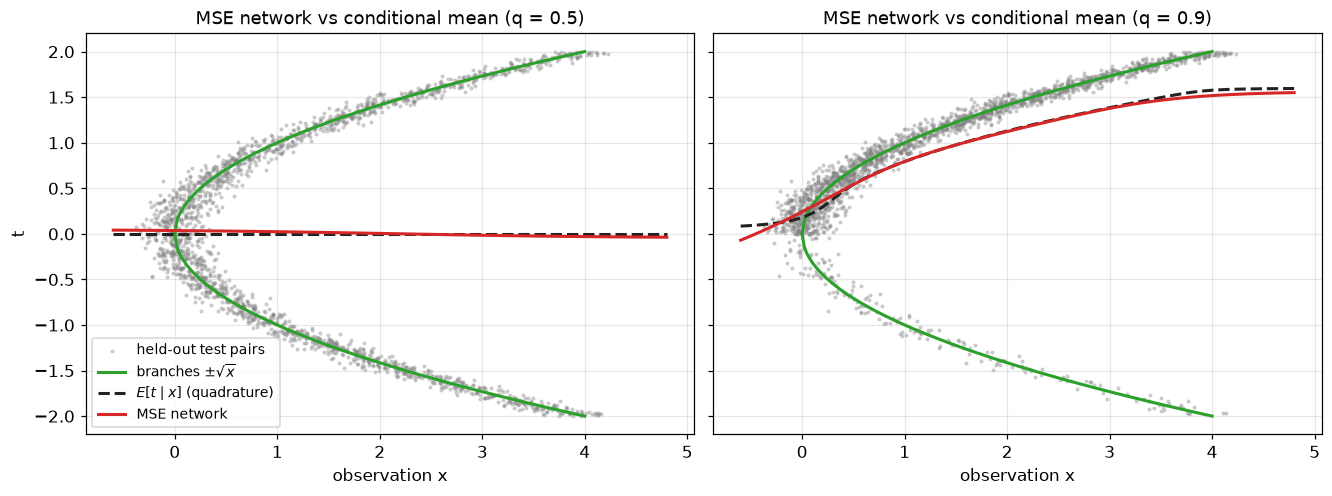

,prior,test_MSE_network,test_MSE_exact_conditional_mean,max_abs_gap_to_E_t_given_x
0,q = 0.5,1.3388,1.3386,0.0410
1,q = 0.9,0.4747,0.4734,0.1542


In [8]:
x_line = np.linspace(-0.6, 4.8, 109)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
mse_rows = []
for ax, (name, (model, hist, ctx)) in zip(axes, mse_models.items()):
    q = ctx.dcfg.q
    x_te, t_te = ctx.splits["test"]
    ref_mean_line = np.array([R.reference_mean(x, A, SIGMA, q) for x in x_line])
    ax.scatter(x_te, t_te, s=3, alpha=0.3, color="grey", label="held-out test pairs")
    xs = np.linspace(0, A**2, 200)
    ax.plot(xs, np.sqrt(xs), color=COLORS["branch"], lw=2, label=r"branches $\pm\sqrt{x}$")
    ax.plot(xs, -np.sqrt(xs), color=COLORS["branch"], lw=2)
    ax.plot(x_line, ref_mean_line, color=COLORS["reference"], ls="--", lw=2, label=r"$E[t\mid x]$ (quadrature)")
    ax.plot(x_line, E.predict_point(model, x_line), color=COLORS["mse"], lw=2, label="MSE network")
    ax.set(xlabel="observation x", title=f"MSE network vs conditional mean ({name})")
    # test MSE of the network vs the best possible (the exact conditional mean)
    ref_mean_test = np.array([R.reference_mean(x, A, SIGMA, q) for x in x_te])
    mse_rows.append(dict(prior=name, test_MSE_network=np.mean((E.predict_point(model, x_te) - t_te) ** 2),
                         test_MSE_exact_conditional_mean=np.mean((ref_mean_test - t_te) ** 2),
                         max_abs_gap_to_E_t_given_x=np.max(np.abs(E.predict_point(model, x_line) - ref_mean_line))))
axes[0].set_ylabel("t"); axes[0].legend(loc="lower left")
savefig(fig, "04_mse_predictions"); plt.show()
display(pd.DataFrame(mse_rows))

The trained network follows the quadrature $\mathbb E[t\mid x]$ closely, and its test MSE is
essentially the best possible: it matches the MSE of the exact conditional mean. So the network is
*correct* for its objective. With $q=0.5$ its output is the flat line near 0, between the two arms of
the data. With $q=0.9$ it bends toward the majority branch, but by theory it should sit at
$\mathbb E[t\mid x] = (2q-1)\,\mathbb E[|t|\mid x]\approx0.8\sqrt{x}$, which is still not on a branch.

### When does the prediction lie *between* the branches rather than *near* one?
We need a rule for "near". The local posterior standard deviation around a branch is
$\sigma/(2\sqrt x)$ (§3.2), so we call the prediction **near the ± branch** if
$|f(x)\mp\sqrt{x}| \le w(x) = 3\,\sigma/(2\sqrt{x})$ (three local standard deviations), and **between
the branches** if $-\sqrt{x}+w < f(x) < \sqrt{x}-w$. We only apply this in the two-branch region
$2\sigma\le x\le a^2$.

In [9]:
def branch_position(f, x, sigma, a, k=3.0):
    # Label each prediction relative to the two inverse branches (see rule above).
    out = []
    for fi, xi in zip(f, x):
        region = R.classify_region(xi, a, sigma)
        if region != "two branches":
            out.append(f"({region})"); continue
        r = np.sqrt(xi); w = k * sigma / (2 * r)
        if abs(fi - r) <= w:   out.append("near + branch")
        elif abs(fi + r) <= w: out.append("near - branch")
        elif -r < fi < r:      out.append("BETWEEN branches")
        else:                  out.append("outside both branches")
    return np.array(out)

def label_ranges(x, labels):
    # Collapse a label sequence over a sorted x grid into contiguous ranges.
    out, start = [], 0
    for i in range(1, len(x) + 1):
        if i == len(x) or labels[i] != labels[start]:
            out.append((labels[start], round(x[start], 3), round(x[i - 1], 3))); start = i
    return pd.DataFrame(out, columns=["position of prediction", "x from", "x to"])

x_fine = np.linspace(-0.5, 4.5, 501)
for name, (model, hist, ctx) in mse_models.items():
    q = ctx.dcfg.q
    print(f"\n=== {name}: trained MSE network ===")
    display(label_ranges(x_fine, branch_position(E.predict_point(model, x_fine), x_fine, SIGMA, A)))
    print(f"=== {name}: exact conditional mean E[t|x] (quadrature) ===")
    ref_m = np.array([R.reference_mean(x, A, SIGMA, q) for x in x_fine])
    display(label_ranges(x_fine, branch_position(ref_m, x_fine, SIGMA, A)))


=== q = 0.5: trained MSE network ===


,position of prediction,x from,x to
0,(no real inverse),-0.50,0.00
1,(merged),0.01,0.29
2,BETWEEN branches,0.30,4.00
3,(beyond support),4.01,4.50


=== q = 0.5: exact conditional mean E[t|x] (quadrature) ===


,position of prediction,x from,x to
0,(no real inverse),-0.50,0.00
1,(merged),0.01,0.29
2,BETWEEN branches,0.30,4.00
3,(beyond support),4.01,4.50



=== q = 0.9: trained MSE network ===


,position of prediction,x from,x to
0,(no real inverse),-0.50,0.00
1,(merged),0.01,0.29
2,near + branch,0.30,1.10
3,BETWEEN branches,1.11,4.00
4,(beyond support),4.01,4.50


=== q = 0.9: exact conditional mean E[t|x] (quadrature) ===


,position of prediction,x from,x to
0,(no real inverse),-0.50,0.00
1,(merged),0.01,0.29
2,near + branch,0.30,1.09
3,BETWEEN branches,1.10,4.00
4,(beyond support),4.01,4.50


**Answer to Part 2.**
* **Symmetric prior:** the MSE prediction lies *between* the branches across the whole two-branch region $x\ge2\sigma$. It sits near 0, which corresponds to neither $+\sqrt x$ nor $-\sqrt x$. Only for $x\le 0$ is predicting 0 sensible, because there the posterior really is a single bump at 0.
* **Asymmetric prior ($q=0.9$):** $\mathbb E[t\mid x]\approx 0.8\sqrt{x}$ is $0.2\sqrt x$ away from the $+$ branch, while the branch width $w(x)$ shrinks like $1/\sqrt x$. So the prediction counts as "near the + branch" only for small $x$ (where the branch is wide) and lies **between** the branches for larger $x$ (see the tables above). An imbalanced prior moves the mean toward the majority branch but never puts it exactly on a branch. The minority branch never appears in a point prediction at all.

### 4.1 Would a different point loss help? Absolute error and the conditional median
Squared error is not special here. Replacing it with absolute error,
$\frac1N\sum_i|f_\theta(x_i)-t_i|$, changes *which* summary of $p(t\mid x)$ the network learns, but it is
still a single number. For fixed $x$,

$$ \frac{d}{df}\,\mathbb E\big[\,|f-t|\;\big|\;x\big] = P(t\le f\mid x)-P(t>f\mid x) = 2F(f\mid x)-1, $$

which is zero at the **conditional median** $F^{-1}(\tfrac12\mid x)$. (In general: squared loss gives the
mean, absolute loss the median, pinball loss a quantile.) The theory predicts two different failures.

* **Symmetric prior:** $F(0\mid x)=\tfrac12$, so the median is 0, between the branches again. Worse,
  almost no probability lies between $-\sqrt x$ and $+\sqrt x$, so $F$ stays at about $\tfrac12$ across the
  *whole* gap and the loss barely changes wherever $f$ sits inside it. The shaded **median band** below
  marks where $F(f\mid x)\in[0.499,\,0.501]$. Anywhere in it, the expected absolute error is within
  $0.002\times$(band width) of the optimum, so the median is only **weakly identified**.
* **Imbalanced prior ($q=0.9$):** $F(0\mid x)=1-q=0.1<\tfrac12$, so the median lies *on the majority
  branch*: it is the point with $0.4/0.9\approx44\%$ of the $+$ branch's mass below it, just under
  $+\sqrt x$. That is a valid inverse, but only one of the two. The minority branch is ignored.

We train the same 3×64 network with absolute error (5 seeds per prior, same data as above) and compare
it with the exact conditional median from quadrature (`R.reference_median`, the midpoint of a vanishingly
narrow median band, which gives exactly 0 in the symmetric case).

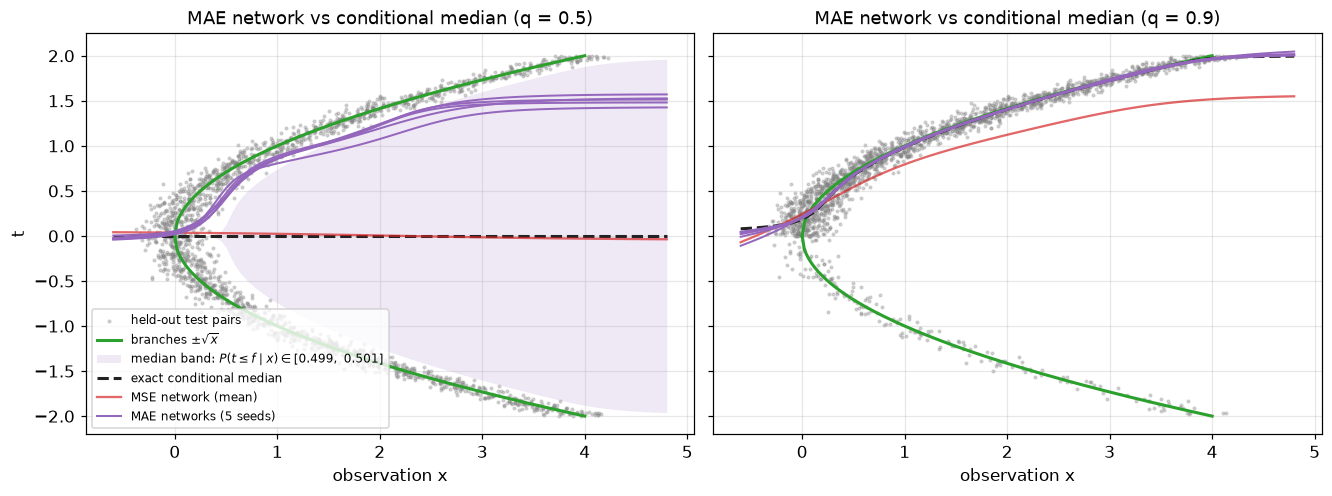

test_MAE        test_MSE        frac_near_plus        frac_between        mean_abs_f2_minus_x       
                         mean    std     mean    std           mean    std         mean    std                mean    std
prior   loss                                                                                                             
q = 0.5 MSE             1.003    NaN    1.339    NaN          0.000    NaN        1.000    NaN               2.150    NaN
        MAE             1.019  0.001    2.271  0.070          0.299  0.051        0.701  0.051               0.702  0.116
        exact median    1.003    NaN    1.339    NaN            NaN    NaN          NaN    NaN                 NaN    NaN
q = 0.9 MSE             0.386    NaN    0.475    NaN          0.218    NaN        0.782    NaN               0.817    NaN
        MAE             0.264  0.000    0.521  0.002          1.000  0.000        0.000  0.000               0.030  0.011
        exact median    0.264    NaN    0.519    NaN            NaN    NaN          NaN    NaN                 NaN    NaN

In [10]:
MAE_SEEDS = SEEDS
mae_models = {name: [train_mae_model(ctx.dcfg, TRAIN, seed=s, splits=ctx.splits, use_cache=USE_CACHE)[0] for s in MAE_SEEDS]
              for name, (_, _, ctx) in mse_models.items()}

x_line = np.linspace(-0.6, 4.8, 109)
x_two = np.linspace(2 * SIGMA, A**2, 400)       # the two-branch region, where "near / between" is defined
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
mae_rows = []
for ax, (name, (mse_model, _, ctx)) in zip(axes, mse_models.items()):
    q = ctx.dcfg.q
    x_te, t_te = ctx.splits["test"]
    ax.scatter(x_te, t_te, s=3, alpha=0.3, color="grey", label="held-out test pairs")
    xs = np.linspace(0, A**2, 200)
    ax.plot(xs, np.sqrt(xs), color=COLORS["branch"], lw=2, label=r"branches $\pm\sqrt{x}$")
    ax.plot(xs, -np.sqrt(xs), color=COLORS["branch"], lw=2)
    band = np.array([R.reference_median_band(x, A, SIGMA, q) for x in x_line])
    ax.fill_between(x_line, band[:, 0], band[:, 1], color=COLORS["mae"], alpha=0.15, lw=0,
                    label=r"median band: $P(t\leq f\mid x) \in [0.499,\ 0.501]$")
    ax.plot(x_line, [R.reference_median(x, A, SIGMA, q) for x in x_line], color=COLORS["reference"], ls="--", lw=2,
            label="exact conditional median")
    ax.plot(x_line, E.predict_point(mse_model, x_line), color=COLORS["mse"], lw=1.5, alpha=0.7, label="MSE network (mean)")
    for i, m in enumerate(mae_models[name]):
        ax.plot(x_line, E.predict_point(m, x_line), color=COLORS["mae"], lw=1.3,
                label=f"MAE networks ({len(MAE_SEEDS)} seeds)" if i == 0 else None)
    ax.set(xlabel="observation x", title=f"MAE network vs conditional median ({name})")

    # scores on held-out data, and where the prediction sits relative to the branches
    med_test = np.array([R.reference_median(x, A, SIGMA, q) for x in x_te])
    for kind, seed, model in [("MSE", 0, mse_model)] + [("MAE", s, m) for s, m in zip(MAE_SEEDS, mae_models[name])]:
        f_te, f_two = E.predict_point(model, x_te), E.predict_point(model, x_two)
        pos = branch_position(f_two, x_two, SIGMA, A)
        mae_rows.append(dict(prior=name, loss=kind, seed=seed,
                             test_MAE=np.mean(np.abs(f_te - t_te)), test_MSE=np.mean((f_te - t_te) ** 2),
                             frac_near_plus=np.mean(pos == "near + branch"), frac_near_minus=np.mean(pos == "near - branch"),
                             frac_between=np.mean(pos == "BETWEEN branches"),
                             mean_abs_f2_minus_x=np.mean(np.abs(f_two**2 - x_two))))
    mae_rows.append(dict(prior=name, loss="exact median", seed=np.nan,
                         test_MAE=np.mean(np.abs(med_test - t_te)), test_MSE=np.mean((med_test - t_te) ** 2)))
axes[0].set_ylabel("t"); axes[0].legend(loc="lower left", fontsize=8)
savefig(fig, "04_mae_predictions"); plt.show()

df_mae = pd.DataFrame(mae_rows)
df_mae.to_csv(RESULTS / "part2_mae_vs_mse.csv", index=False)
display(df_mae.groupby(["prior", "loss"], sort=False).agg(["mean", "std"]).drop(columns="seed")
        [["test_MAE", "test_MSE", "frac_near_plus", "frac_between", "mean_abs_f2_minus_x"]].round(3))

**Results of §4.1.**
* **$q=0.5$:** the MAE networks never show both branches, and they are not even stable. Each seed
  settles somewhere different inside the median band, and part of each curve drifts up onto the $+$
  branch (in our run, 21–34% of the two-branch region counts as "near +", the rest "between"). The upward
  pull comes from the training sample, which happens to contain 50.8% positive $t$. With a flat loss, a
  tiny sampling imbalance decides where the prediction goes. Even so, their test MAE (about 1.02) is
  within 2% of the exact median's (1.003), while their test MSE is much worse (about 2.3 vs 1.34). A small
  gap in a point loss can hide very different predictions.
* **$q=0.9$:** the MAE networks match the exact median (test MAE 0.264 for every seed, equal to the
  exact median's) and lie **near the $+$ branch across the whole two-branch region** (100%, against
  about 22% for the MSE network). Their predictions are valid inverses: $|f(x)^2-x|$ averages about 0.03,
  against about 0.8 for the MSE network.
* **Conclusion:** the point loss only decides *which single answer* comes out: between the branches
  (mean), anywhere in the gap (median, symmetric prior), or on the majority branch (median, imbalanced
  prior). None of them can say that $-\sqrt x$ is also a valid answer. For that we need a model of the
  whole distribution, which is the next section.

## 5. Part 3: mixture density network

### 5.1 Model
$$ p_\theta(t\mid x)=\sum_{j=1}^{M}\pi_j(x)\,\mathcal N\big(t\mid\mu_j(x),v_j(x)\big). $$

A shared MLP trunk maps the (standardised) scalar $x$ to a hidden vector $h(x)$. Three linear heads
then produce, for each component $j$:

| Head output | Transformation | Guarantees |
|---|---|---|
| logits $\alpha_j(x)$ | $\pi_j = \mathrm{softmax}(\alpha)_j = e^{\alpha_j}/\sum_k e^{\alpha_k}$ (implemented as `log_softmax`) | $\pi_j>0$, $\sum_j\pi_j=1$ |
| means $\mu_j(x)$ | none | any real value |
| raw $s_j(x)$ | $v_j=\mathrm{softplus}(s_j)+v_{\min}$, $v_{\min}=10^{-4}$ | $v_j > v_{\min}>0$ |

$v_j$ is a **variance** (std $=\sqrt{v_j}$). The floor $v_{\min}=10^{-4}$ means no component can be
narrower than std 0.01. This stops a component from collapsing onto a few training points, which
would make the likelihood blow up.

### 5.2 Likelihood objective
For i.i.d. data, the likelihood is $\prod_i p_\theta(t_i\mid x_i)$. Taking the negative log and
averaging gives

$$ \mathcal L_{\rm MDN}(\theta) = -\frac1N\sum_{i=1}^N \log\Big[\sum_{j=1}^M \pi_j(x_i)\,\mathcal N(t_i\mid\mu_j(x_i),v_j(x_i))\Big]. $$

**Stable evaluation.** Summing tiny Gaussian densities can underflow to 0, and then $\log 0=-\infty$.
Instead we work entirely in log space:

$$ \log p_\theta(t\mid x)=\operatorname{logsumexp}_j\Big[\log\pi_j(x) - \tfrac12\log(2\pi v_j) - \tfrac{(t-\mu_j)^2}{2v_j}\Big], $$

with $\log\pi_j$ from `log_softmax` and `torch.logsumexp`, which subtracts the maximum before
exponentiating. The **single-Gaussian conditional network** $\mathcal N(\mu_\theta(x),v_\theta(x))$ is
exactly this model with $M=1$. We reuse the same code, trained with Gaussian NLL, so the two models
differ only in $M$.

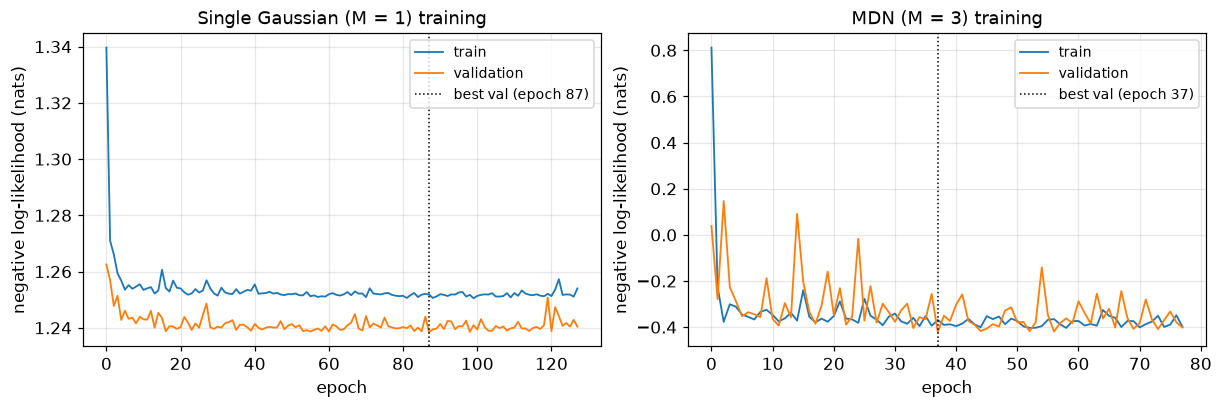

1062

In [11]:
sg_model, sg_hist, sg_settings = train_single_gaussian_model(BASE_DATA, TRAIN, var_floor=BASE_MDN.var_floor, seed=0,
                                                             splits=base.splits, use_cache=USE_CACHE, verbose=True)
mdn_model, mdn_hist, mdn_settings = train_mdn(BASE_DATA, TRAIN, BASE_MDN, seed=0, splits=base.splits,
                                              use_cache=USE_CACHE, verbose=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_history(axes[0], sg_hist, "Single Gaussian (M = 1) training", "negative log-likelihood (nats)")
plot_history(axes[1], mdn_hist, f"MDN (M = {BASE_MDN.M}) training", "negative log-likelihood (nats)")
savefig(fig, "05_nll_training"); plt.show()

# save trained weights + settings for reproducibility
for name, model, s in [("single_gaussian", sg_model, sg_settings), ("mdn_M3", mdn_model, mdn_settings), ("mse", mse_models["q = 0.5"][0], None)]:
    torch.save(model.state_dict(), CKPT / f"baseline_{name}.pt")
(RESULTS / "baseline_model_settings.json").write_text(json.dumps({"single_gaussian": sg_settings, "mdn": mdn_settings}, indent=2))

Both NLL curves converge, and the best-validation weights (dotted line) are restored. The MDN reaches
a much lower NLL than the single Gaussian. A single Gaussian has to cover both branches with one wide
bell, so its NLL levels off far higher.

### 5.3 Implementation checks

In [12]:
x_te, t_te = base.splits["test"]
for name, m in [("single Gaussian (M=1)", sg_model), (f"MDN (M={BASE_MDN.M})", mdn_model)]:
    pi, mu, var = E.mdn_params(m, x_te)
    nll, se = E.evaluate_nll(m, x_te, t_te)
    print(f"{name:22s} max|sum(pi)-1| = {np.abs(pi.sum(1) - 1).max():.1e} | min variance = {var.min():.2e} "
          f"(floor {BASE_MDN.var_floor:g}) | all finite: {np.isfinite(var).all() and np.isfinite(mu).all()} | "
          f"test NLL = {nll:.4f} (finite: {np.isfinite(nll)})")

# torch log-likelihood vs an independent NumPy implementation
pi, mu, var = E.mdn_params(mdn_model, x_te[:5])
manual = np.log((pi * norm.pdf(t_te[:5, None], mu, np.sqrt(var))).sum(1))   # note: scipy wants a STD
with torch.no_grad():
    torch_lp = mdn_model.log_prob(torch.tensor(t_te[:5], dtype=torch.float32, device=DEVICE),
                                  torch.tensor(x_te[:5], dtype=torch.float32, device=DEVICE)).cpu().numpy()
print("max |torch - numpy| log-density on 5 test points:", np.abs(manual - torch_lp).max())

# why logsumexp matters: a t far from every component
xt = torch.tensor([1.0], device=DEVICE); tt = torch.tensor([30.0], device=DEVICE)
with torch.no_grad():
    lp, m_, v_ = mdn_model(xt)
    naive = torch.log((lp.exp() * torch.exp(-0.5 * (tt[:, None] - m_) ** 2 / v_) / torch.sqrt(2 * np.pi * v_)).sum())
    stable = mdn_model.log_prob(tt, xt)
print(f"log p(t=30 | x=1): naive sum of densities -> {naive.item()},  logsumexp -> {stable.item():.1f}")

single Gaussian (M=1)  max|sum(pi)-1| = 0.0e+00 | min variance = 3.21e-02 (floor 0.0001) | all finite: True | test NLL = 1.2394 (finite: True)
MDN (M=3)              max|sum(pi)-1| = 1.8e-07 | min variance = 1.43e-03 (floor 0.0001) | all finite: True | test NLL = -0.4113 (finite: True)
max |torch - numpy| log-density on 5 test points: 5.960173461438956e-07
log p(t=30 | x=1): naive sum of densities -> -inf,  logsumexp -> -3105.3


The mixture weights sum to one to float precision, every variance is strictly above the floor and
finite, and the test log-likelihood is finite. Our PyTorch log-density matches an independent NumPy
computation. For a point far in the tail, the naive "sum the densities, then log" gives $-\infty$
because of underflow, while the `logsumexp` form returns the correct large negative number. During
training, such an underflow would produce infinite losses and NaN gradients.

### 5.4 What did the MDN learn? Components as functions of $x$

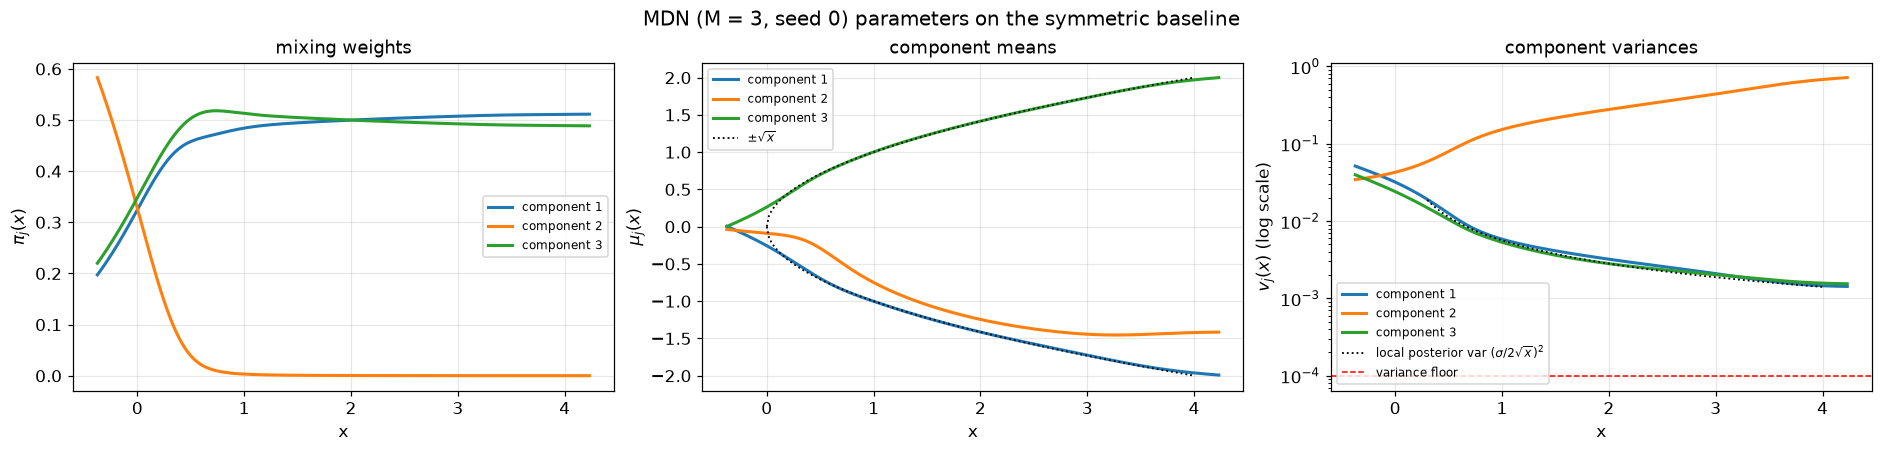

In [13]:
x_line = np.linspace(x_te.min(), x_te.max(), 400)
pi, mu, var = E.mdn_params(mdn_model, x_line)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for j in range(pi.shape[1]):
    axes[0].plot(x_line, pi[:, j], lw=2, label=f"component {j+1}")
    axes[1].plot(x_line, mu[:, j], lw=2, label=f"component {j+1}")
    axes[2].semilogy(x_line, var[:, j], lw=2, label=f"component {j+1}")
xs = np.linspace(0, A**2, 200)
axes[1].plot(xs, np.sqrt(xs), "k:", lw=1.2, label=r"$\pm\sqrt{x}$"); axes[1].plot(xs, -np.sqrt(xs), "k:", lw=1.2)
xp = np.linspace(2 * SIGMA, A**2, 200)
axes[2].semilogy(xp, (SIGMA / (2 * np.sqrt(xp))) ** 2, "k:", lw=1.2, label=r"local posterior var $(\sigma/2\sqrt{x})^2$")
axes[2].axhline(BASE_MDN.var_floor, color="r", ls="--", lw=1, label="variance floor")
axes[0].set(xlabel="x", ylabel=r"$\pi_j(x)$", title="mixing weights")
axes[1].set(xlabel="x", ylabel=r"$\mu_j(x)$", title="component means")
axes[2].set(xlabel="x", ylabel=r"$v_j(x)$ (log scale)", title="component variances")
for ax in axes: ax.legend(fontsize=8)
fig.suptitle(f"MDN (M = {BASE_MDN.M}, seed 0) parameters on the symmetric baseline")
savefig(fig, "05_mdn_components"); plt.show()

**How to read this.** Where the posterior has two branches, the component means follow
$+\sqrt{x}$ and $-\sqrt{x}$, and the weights on the two branch components settle near 0.5 each. Where
the branches are distinct, the variances of the branch components track the theoretical local
posterior variance $(\sigma/2\sqrt{x})^2$ and stay well above the floor. Near and below $x=0$ the
components overlap, and the spare component is free to help shape the merged, non-Gaussian bump.
Mixture components are **not** the same as modes: three components can still add up to a density
with one or two modes. Below we compare the *combined* density with the reference directly.

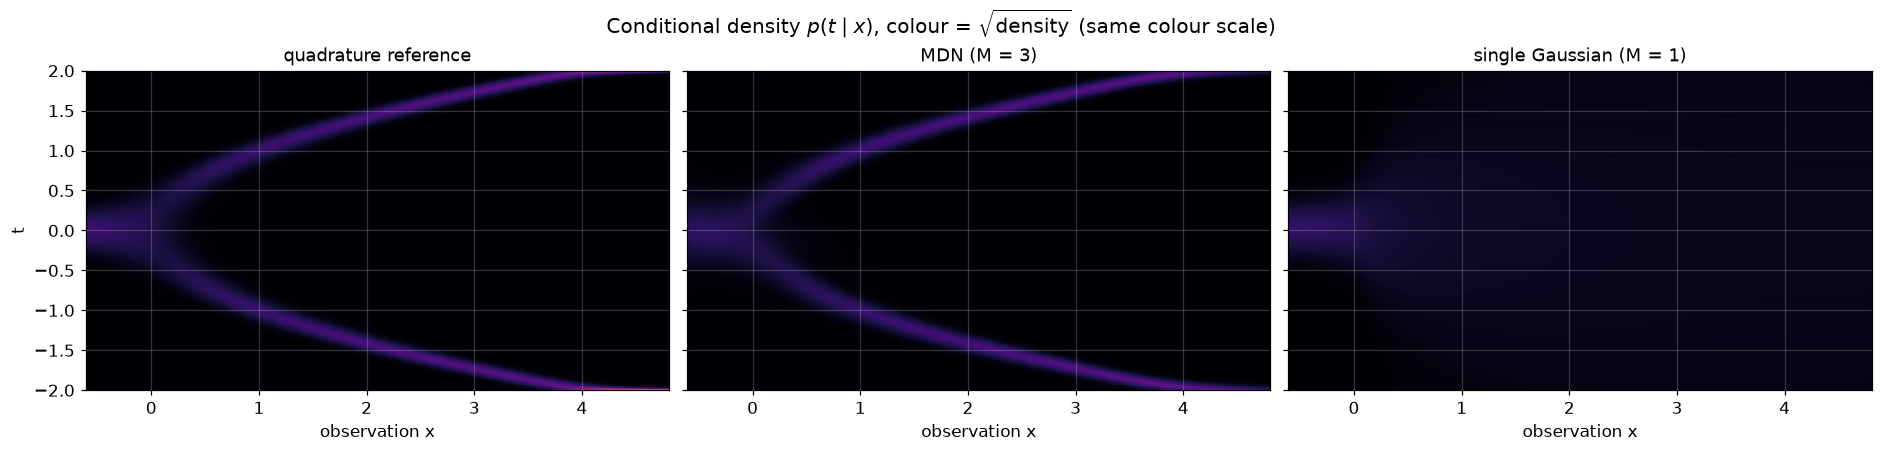

In [14]:
x_hm = np.linspace(-0.6, 4.8, 271)
pred_hm = E.predict_conditional_density(mdn_model, x_hm, t_hm)
sg_hm = E.predict_conditional_density(sg_model, x_hm, t_hm)
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, d, title in [(axes[0], dens_hm, "quadrature reference"), (axes[1], pred_hm, f"MDN (M = {BASE_MDN.M})"),
                     (axes[2], sg_hm, "single Gaussian (M = 1)")]:
    ax.pcolormesh(x_hm, t_hm, np.sqrt(d.T), shading="auto", cmap="magma", vmin=0, vmax=np.sqrt(dens_hm).max())
    ax.set(xlabel="observation x", title=title)
axes[0].set_ylabel("t")
fig.suptitle(r"Conditional density $p(t\mid x)$, colour = $\sqrt{\mathrm{density}}$ (same colour scale)")
savefig(fig, "05_density_heatmaps"); plt.show()

The MDN reproduces the split ridge of the reference almost exactly. The single Gaussian can only
draw one wide band centred at $t\approx0$, putting most of its probability where the reference has
almost none.

## 6. Part 4: held-out comparison with the single-Gaussian network and the quadrature reference

**Question.** On the same held-out test set, how much better does the MDN describe $p(t\mid x)$
than a single Gaussian, and how close does it get to the exact posterior?
**Held fixed:** baseline data ($q=0.5$, $\sigma=0.15$), training protocol, test set.
**Varied:** number of components $M\in\{1,2,3,5\}$ ($M=1$ = single-Gaussian network), 5 initialisation seeds each.
**Metrics:** test NLL (nats, lower is better), *excess NLL* = model NLL $-$ reference NLL (the exact posterior's NLL on the same test points is the best achievable; the excess estimates the average KL divergence), Wasserstein-1 distance to the reference, branch-probability error, and predicted mass outside $[-a,a]$. All metrics are defined in `p8/evaluate.py` and explained in §8.

In [15]:
print(f"Reference (exact posterior) test NLL on the baseline test set: {base.ref_nll:.4f} nats")
df_base = run_sweep([(BASE_DATA, MDNConfig(M=M)) for M in M_LIST], TRAIN, SEEDS, use_cache=USE_CACHE)
df_base.to_csv(RESULTS / "part4_baseline_M_sweep.csv", index=False)
cols = ["test_nll", "excess_nll", "w1", "branch_err", "recovered_pos", "recovered_neg", "out_mass"]
display(mean_sd_table(df_base, "M", cols))

Reference (exact posterior) test NLL on the baseline test set: -0.4386 nats


  10/20 runs done


  20/20 runs done


,test_nll,excess_nll,w1,branch_err,recovered_pos,recovered_neg,out_mass
M,,,,,,,
1,1.240 ± 0.000,1.678 ± 0.000,0.448 ± 0.000,0.015 ± 0.004,0.086 ± 0.021,0.048 ± 0.000,0.094 ± 0.002
2,-0.412 ± 0.004,0.027 ± 0.004,0.036 ± 0.009,0.016 ± 0.005,1.000 ± 0.000,1.000 ± 0.000,0.009 ± 0.001
3,-0.409 ± 0.007,0.030 ± 0.007,0.040 ± 0.022,0.017 ± 0.010,1.000 ± 0.000,1.000 ± 0.000,0.007 ± 0.001
5,-0.412 ± 0.006,0.027 ± 0.006,0.047 ± 0.022,0.023 ± 0.015,1.000 ± 0.000,1.000 ± 0.000,0.008 ± 0.002


*(Values are mean ± standard deviation over 5 initialisation seeds; $M=1$ is the single-Gaussian network.)*

In [16]:
# ---- one representative model of each kind (seed 0) side by side ----
x_eval = base.x_eval
mse_model0 = mse_models["q = 0.5"][0]
ref_mean_test = np.array([R.reference_mean(x, A, SIGMA) for x in x_te])
rows = [dict(model="MSE network (point)", test_NLL=np.nan, test_MSE_of_point_summary=np.mean((E.predict_point(mse_model0, x_te) - t_te) ** 2),
             W1=np.nan, branch_err=np.nan, out_of_support_mass=np.nan)]
for name, m in [("single Gaussian (M=1)", sg_model), (f"MDN (M={BASE_MDN.M})", mdn_model)]:
    rows.append(dict(model=name, test_NLL=E.evaluate_nll(m, x_te, t_te)[0],
                     test_MSE_of_point_summary=np.mean((E.mixture_mean(m, x_te) - t_te) ** 2),
                     W1=E.evaluate_wasserstein(m, x_eval, T_GRID, A, SIGMA, 0.5, ref=base.ref_eval).mean(),
                     branch_err=np.mean(np.abs(E.model_branch_probability(m, x_eval) - 0.5)),
                     out_of_support_mass=E.out_of_support_mass(m, x_eval, A).mean()))
rows.append(dict(model="exact posterior (quadrature)", test_NLL=base.ref_nll,
                 test_MSE_of_point_summary=np.mean((ref_mean_test - t_te) ** 2), W1=0.0, branch_err=0.0, out_of_support_mass=0.0))
display(pd.DataFrame(rows).set_index("model"))

,test_NLL,test_MSE_of_point_summary,W1,branch_err,out_of_support_mass
model,,,,,
MSE network (point),NaN,1.3388,NaN,NaN,NaN
single Gaussian (M=1),1.2394,1.3394,0.4480,0.0155,0.0933
MDN (M=3),-0.4113,1.3384,0.0274,0.0142,0.0070
exact posterior (quadrature),-0.4386,1.3386,0.0000,0.0000,0.0000


Note the column *test_MSE_of_point_summary*: the MSE network, the single Gaussian (its mean), the MDN
(its mixture mean) and the exact posterior mean all have **almost the same MSE**. By MSE alone you
could not tell that the single Gaussian badly misrepresents the posterior. NLL and W1 make the
difference obvious. We come back to this in §7.4.

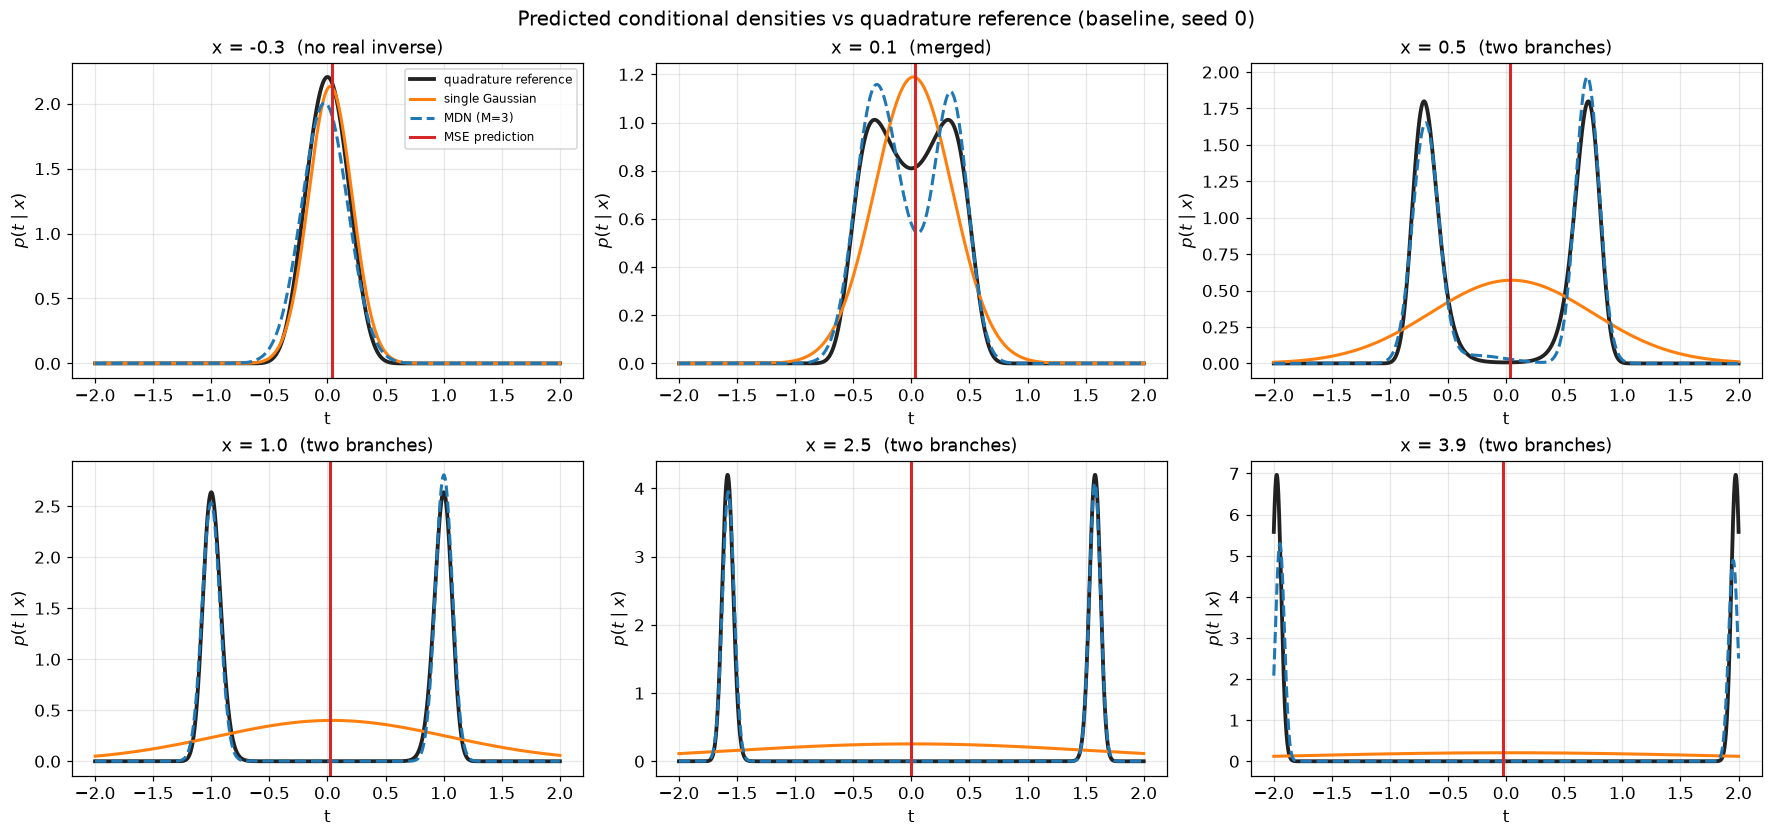

In [17]:
# ---- predicted densities vs the reference at selected observations ----
x_sel = [-0.3, 0.1, 0.5, 1.0, 2.5, 3.9]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, x in zip(axes.flat, x_sel):
    ax.plot(T_GRID, R.reference_density_grid([x], T_GRID, A, SIGMA)[0], color=COLORS["reference"], lw=2.5, label="quadrature reference")
    ax.plot(T_GRID, E.predict_conditional_density(sg_model, [x], T_GRID)[0], color=COLORS["single"], lw=2, label="single Gaussian")
    ax.plot(T_GRID, E.predict_conditional_density(mdn_model, [x], T_GRID)[0], color=COLORS["mdn"], lw=2, ls="--", label=f"MDN (M={BASE_MDN.M})")
    ax.axvline(E.predict_point(mse_model0, [x])[0], color=COLORS["mse"], lw=2, label="MSE prediction")
    ax.set(title=f"x = {x}  ({R.classify_region(x, A, SIGMA)})", xlabel="t", ylabel=r"$p(t\mid x)$")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Predicted conditional densities vs quadrature reference (baseline, seed 0)")
savefig(fig, "06_density_comparison"); plt.show()

In the two-branch region ($x=0.5, 1, 2.5$) the MDN lies on top of the reference's two peaks. The
single Gaussian is one wide bump centred near 0, exactly where the reference density is lowest. The
MSE prediction (red line) also sits in that valley. For negative $x$ ($-0.3$) the reference is a
single bump, and all models, the single Gaussian included, describe it reasonably. In the merged
region ($x=0.1$) the reference has two overlapping bumps with only a shallow dip. The MDN gets the
two bump locations right but makes the dip too deep, and the single Gaussian misses the dip entirely.
Near the upper boundary ($x=3.9$) the reference peaks are sharp and cut off at $\pm2$. The MDN's
peaks are lower than the reference's, because a Gaussian cannot produce a hard edge, and a little of
its mass leaks outside $[-2,2]$. These merged and boundary regions are where the MDN's remaining
errors are concentrated.

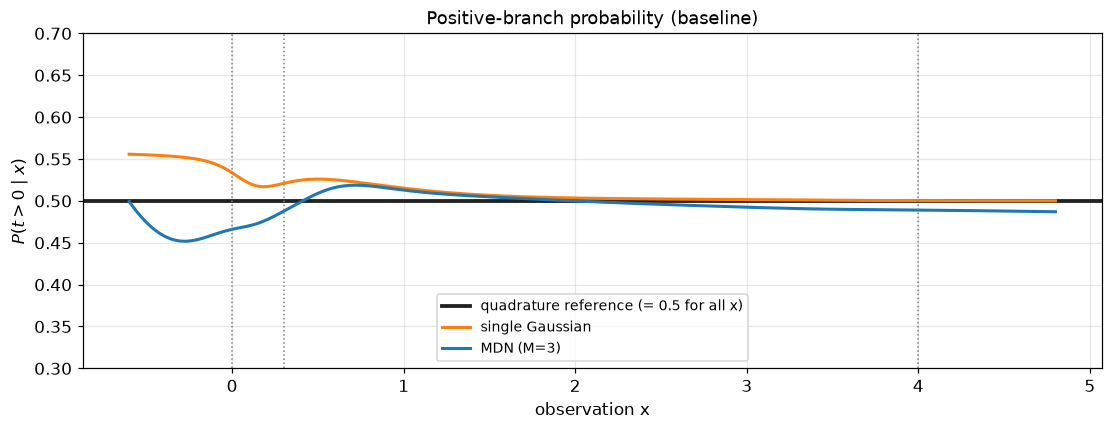

model,MDN (M=3),single Gaussian
region,,
beyond support,0.0111,0.0002
merged,0.0269,0.0220
no real inverse,0.0405,0.0440
two branches,0.0077,0.0101


In [18]:
# ---- branch probabilities P(t > 0 | x) ----
x_line = np.linspace(-0.6, 4.8, 300)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhline(0.5, color=COLORS["reference"], lw=2.5, label="quadrature reference (= 0.5 for all x)")
ax.plot(x_line, E.model_branch_probability(sg_model, x_line), color=COLORS["single"], lw=2, label="single Gaussian")
ax.plot(x_line, E.model_branch_probability(mdn_model, x_line), color=COLORS["mdn"], lw=2, label=f"MDN (M={BASE_MDN.M})")
for xv in (0, 2 * SIGMA, A**2): ax.axvline(xv, color="grey", ls=":", lw=1)
ax.set(xlabel="observation x", ylabel=r"$P(t>0\mid x)$", ylim=(0.3, 0.7), title="Positive-branch probability (baseline)")
ax.legend(); savefig(fig, "06_branch_probability"); plt.show()

regions = np.array([R.classify_region(x, A, SIGMA) for x in x_eval])
rows = []
for name, m in [("single Gaussian", sg_model), (f"MDN (M={BASE_MDN.M})", mdn_model)]:
    err = np.abs(E.model_branch_probability(m, x_eval) - 0.5)
    for reg in ["no real inverse", "merged", "two branches", "beyond support"]:
        rows.append(dict(model=name, region=reg, n_inputs=int((regions == reg).sum()), mean_abs_branch_err=err[regions == reg].mean()))
display(pd.DataFrame(rows).pivot(index="region", columns="model", values="mean_abs_branch_err"))

Both probabilistic models get the 50:50 sign split roughly right, with average errors of a few
hundredths. The MDN's error is smallest in the two-branch region and largest for $x\le0$. There the
single bump is centred at 0, so the sign split depends on tiny shifts of the bump. A single Gaussian
centred near 0 has $P(t>0)\approx0.5$ almost automatically. This shows again that a correct branch probability does
**not** imply a correct density: the single Gaussian's sign split is fine while its shape is badly
wrong. Branch probability must always be read together with NLL, W1 and the density plots.

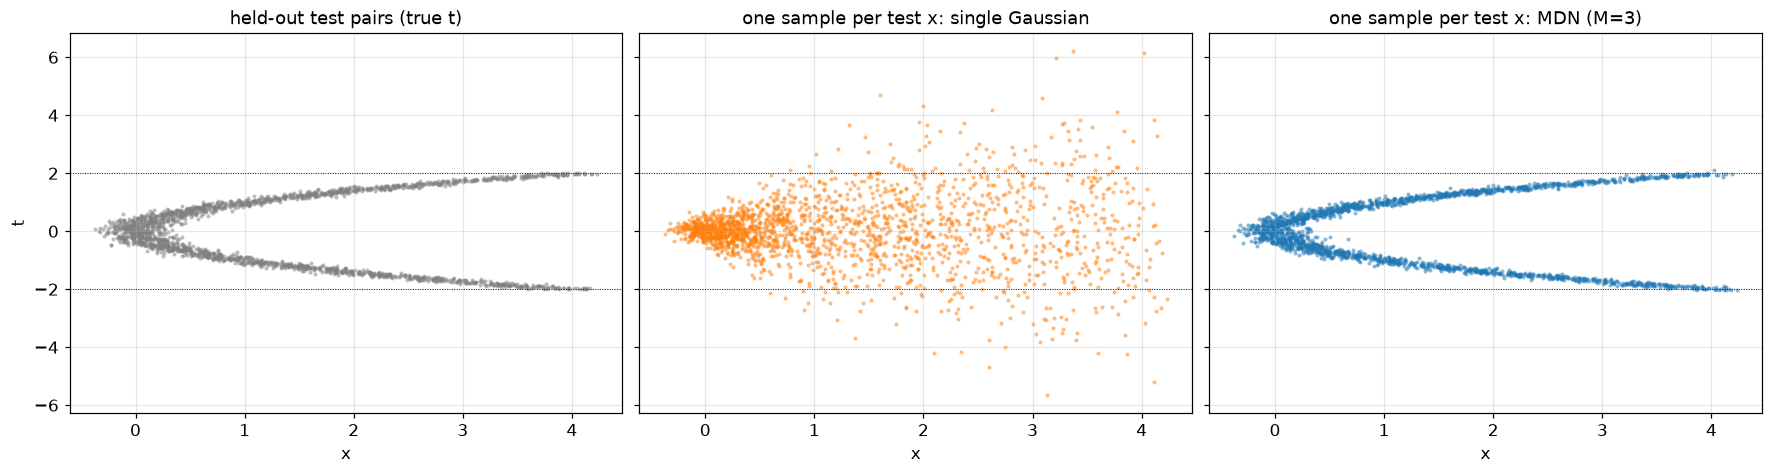

In [19]:
# ---- samples from the predicted conditionals (one per test x) ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
axes[0].scatter(x_te, t_te, s=3, alpha=0.4, color="grey")
axes[0].set(title="held-out test pairs (true t)", xlabel="x", ylabel="t")
for ax, (name, m, c) in zip(axes[1:], [("single Gaussian", sg_model, COLORS["single"]), (f"MDN (M={BASE_MDN.M})", mdn_model, COLORS["mdn"])]):
    s = E.sample_conditional(m, x_te, 1, seed=1)[:, 0]
    ax.scatter(x_te, s, s=3, alpha=0.4, color=c)
    ax.set(title=f"one sample per test x: {name}", xlabel="x")
for ax in axes: ax.axhline(A, color="k", lw=0.6, ls=":"); ax.axhline(-A, color="k", lw=0.6, ls=":")
savefig(fig, "06_samples"); plt.show()

If a model's conditional density is correct, then pairs $(x_i, \tilde t_i)$ with $\tilde t_i\sim p_\theta(t\mid x_i)$
have the same joint distribution as the real test pairs. The MDN samples reproduce the two arms. The
single-Gaussian samples fill the region between the arms, which contains almost no real data, and
spill outside the prior support $|t|\le2$ (dotted lines).

### Forward residuals $r = x - \tilde t^2$, without treating $x=t^2$ as exact
The observation model is $x=t^2+\epsilon$. For the **true** pair, $x-t^2=\epsilon\sim\mathcal N(0,\sigma^2)$,
so even the correct $t$ does not satisfy $x=t^2$ exactly. We should not expect residual zero. A useful
fact follows: if $\tilde t$ is drawn from the **correct** posterior, then $(x,\tilde t)$ has the same
joint law as $(x,t)$, so across the data distribution **$r$ is again $\mathcal N(0,\sigma^2)$**.
A good conditional model should therefore give residuals with standard deviation about
$\sigma=0.15$, not 0. For the MSE network, $r=x-f(x)^2\approx x$ for positive $x$.

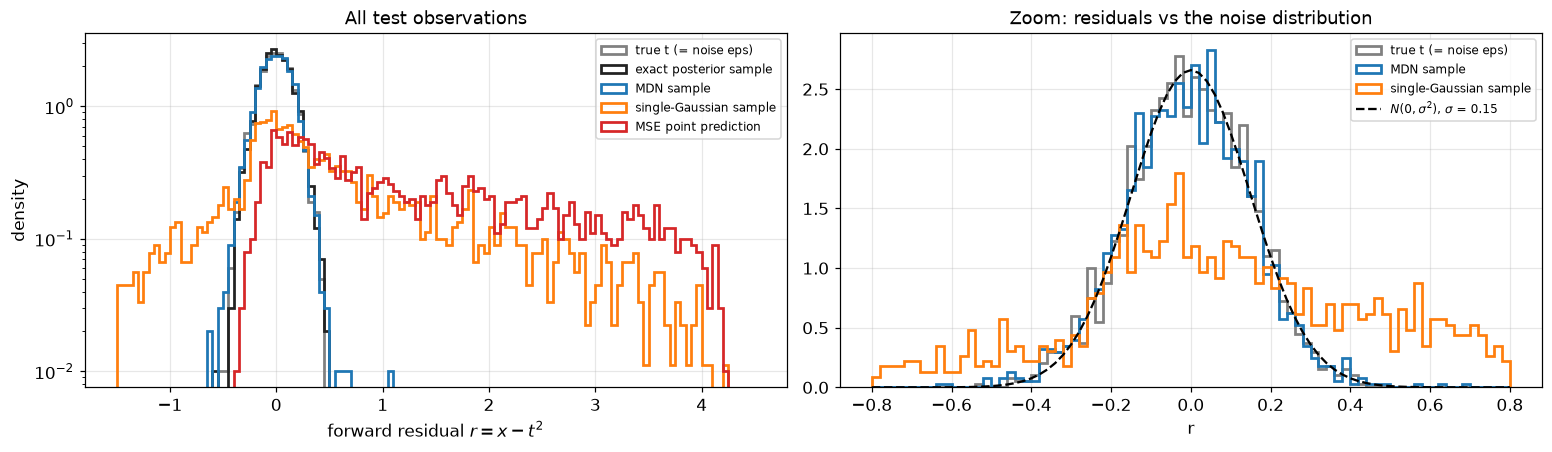

mean of r:


region,all,beyond support,merged,no real inverse,two branches
source,,,,,
MDN sample,-0.007,0.124,-0.008,-0.164,0.010
MSE point prediction,1.333,4.100,0.148,-0.101,1.743
exact posterior sample,-0.002,0.191,-0.004,-0.152,0.014
single-Gaussian sample,-0.028,0.184,-0.015,-0.158,-0.018
true t (= noise eps),-0.005,0.193,0.000,-0.150,0.008


standard deviation of r:


region,all,beyond support,merged,no real inverse,two branches
source,,,,,
MDN sample,0.161,0.146,0.135,0.109,0.161
MSE point prediction,1.198,0.056,0.087,0.080,1.050
exact posterior sample,0.150,0.098,0.126,0.090,0.149
single-Gaussian sample,2.626,5.714,0.225,0.122,2.991
true t (= noise eps),0.151,0.064,0.123,0.096,0.153


fraction of |r| <= 2 sigma:


region,all,beyond support,merged,no real inverse,two branches
source,,,,,
MDN sample,0.940,0.909,0.965,0.888,0.942
MSE point prediction,0.259,0.000,1.000,0.978,0.002
exact posterior sample,0.952,0.818,0.977,0.910,0.953
single-Gaussian sample,0.350,0.045,0.927,0.904,0.152
true t (= noise eps),0.951,0.955,0.985,0.921,0.947


In [20]:
r_true = x_te - t_te**2
r_ref  = x_te - E.sample_reference(x_te, T_GRID, A, SIGMA, 0.5, 1, seed=2)[:, 0] ** 2
r_sg   = x_te - E.sample_conditional(sg_model, x_te, 1, seed=2)[:, 0] ** 2
r_mdn  = x_te - E.sample_conditional(mdn_model, x_te, 1, seed=2)[:, 0] ** 2
r_mse  = x_te - E.predict_point(mse_model0, x_te) ** 2
res = {"true t (= noise eps)": r_true, "exact posterior sample": r_ref, "MDN sample": r_mdn,
       "single-Gaussian sample": r_sg, "MSE point prediction": r_mse}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.linspace(-1.5, 4.5, 121)
for (name, r), c in zip(res.items(), ["grey", COLORS["reference"], COLORS["mdn"], COLORS["single"], COLORS["mse"]]):
    axes[0].hist(r, bins=bins, density=True, histtype="step", lw=1.8, color=c, label=name)
axes[0].set(xlabel=r"forward residual $r = x - t^2$", ylabel="density", title="All test observations", yscale="log")
zoom = np.linspace(-0.8, 0.8, 81)
for name in ["true t (= noise eps)", "MDN sample", "single-Gaussian sample"]:
    axes[1].hist(res[name], bins=zoom, density=True, histtype="step", lw=1.8, label=name,
                 color={"true t (= noise eps)": "grey", "MDN sample": COLORS["mdn"], "single-Gaussian sample": COLORS["single"]}[name])
axes[1].plot(zoom, norm.pdf(zoom, 0, SIGMA), "k--", lw=1.5, label=r"$N(0,\sigma^2)$, $\sigma$ = 0.15")
axes[1].set(xlabel="r", title="Zoom: residuals vs the noise distribution")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
savefig(fig, "06_forward_residuals"); plt.show()

reg_te = np.array([R.classify_region(x, A, SIGMA) for x in x_te])
rows = []
for name, r in res.items():
    for reg in ["all", "no real inverse", "merged", "two branches", "beyond support"]:
        mask = np.ones_like(r, bool) if reg == "all" else reg_te == reg
        rows.append(dict(source=name, region=reg, n=int(mask.sum()), mean_r=r[mask].mean(), sd_r=r[mask].std(),
                         frac_within_2sigma=np.mean(np.abs(r[mask]) <= 2 * SIGMA)))
resid_table = pd.DataFrame(rows)
print("mean of r:"); display(resid_table.pivot(index="source", columns="region", values="mean_r").round(3))
print("standard deviation of r:"); display(resid_table.pivot(index="source", columns="region", values="sd_r").round(3))
print("fraction of |r| <= 2 sigma:")
display(resid_table.pivot(index="source", columns="region", values="frac_within_2sigma").round(3))

**Interpretation.**
* The true pairs and the exact-posterior samples both have residual standard deviation close to $\sigma$, and about 95% of residuals fall within $\pm2\sigma$, as expected for $\mathcal N(0,\sigma^2)$. This is the benchmark, and it is **not** zero.
* The MDN samples come close to that benchmark in every region, with a slightly larger spread overall and beyond the support. This is a forward-model consistency check: the sampled inverses explain the observations nearly as well as the true inverses.
* The single-Gaussian samples have a far wider residual spread in the two-branch region and beyond the support. Many of its samples fall between the branches, or outside $|t|\le2$, where $t^2$ is far from $x$.
* The MSE point prediction has residual $\approx x$ for positive observations. Only about 0.2% of its residuals in the two-branch region are within $\pm2\sigma$. It is consistent with the data only near $x\approx0$.
* Region by region, a non-zero *mean* residual can be the correct answer. Beyond the support ($x>a^2$) the residual is positive, because $t^2\le4$ cannot reach $x$. For negative $x$ it is negative, because $t^2\ge0$ cannot go below 0. The exact posterior samples show the same shifts, so residuals should always be compared with the noise level and with the reference, never with zero.

## 7. Part 5: asymmetric prior, missing branches and sensitivity

**Question.** If one sign branch is rare in the training data, does the MDN still recover it? Does
that depend on $M$, initialisation or the variance floor?
**Changed:** the prior, $q=P(t>0)\in\{0.5,0.7,0.9,0.97\}$, so the **negative branch is the minority**
(weight $1-q$). The likelihood, $\sigma=0.15$, sample sizes and training protocol are unchanged.
**Known answer:** the exact posterior has $P(t>0\mid x)=q$ for every $x$ (§3.1 checks), and its shape
on each side is the symmetric one rescaled by $2q$ or $2(1-q)$.
**Metrics:** excess NLL, branch-probability error $|\hat P_+ - q|$, minority-branch *capture* (mass the
model puts in the neighbourhood of $-\sqrt x$ divided by the reference mass there) and *recovery
rate* (fraction of the 21 two-branch inputs where capture $\ge 0.5$). Definitions are in §8.

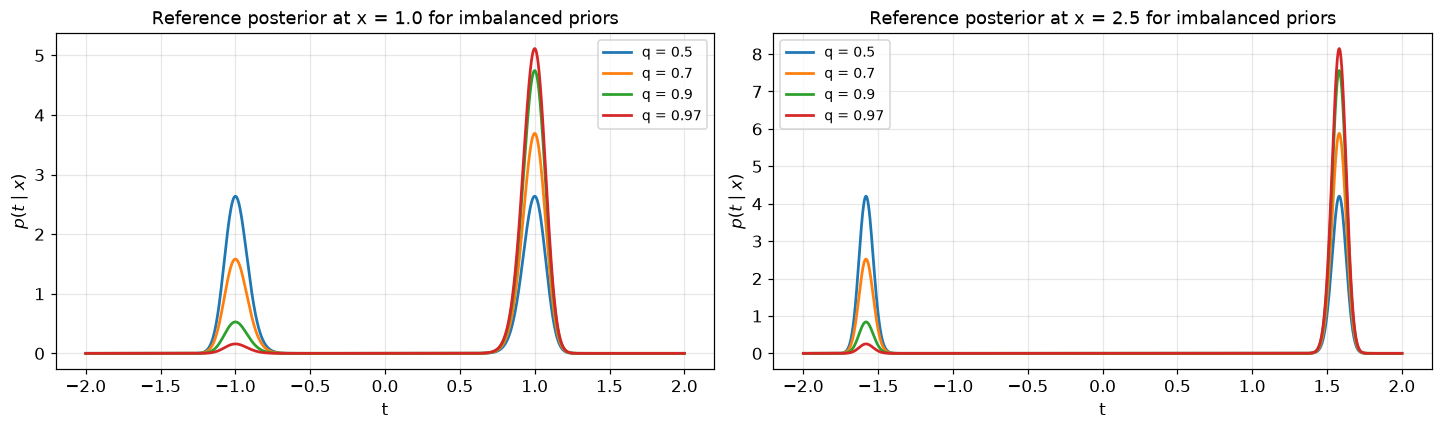

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, x in zip(axes, [1.0, 2.5]):
    for q in Q_LIST:
        ax.plot(T_GRID, R.reference_density_grid([x], T_GRID, A, SIGMA, q)[0], lw=1.8, label=f"q = {q}")
    ax.set(xlabel="t", ylabel=r"$p(t\mid x)$", title=f"Reference posterior at x = {x} for imbalanced priors")
    ax.legend()
savefig(fig, "07_asym_reference"); plt.show()

In [22]:
df_asym = run_sweep([(replace(BASE_DATA, q=q), MDNConfig(M=M)) for q in Q_LIST for M in M_LIST], TRAIN, SEEDS, use_cache=USE_CACHE)
df_asym.to_csv(RESULTS / "part5_asymmetric_prior_sweep.csv", index=False)
display(mean_sd_table(df_asym, ["q", "M"], ["excess_nll", "branch_err", "w1", "capture_neg", "recovered_neg", "out_mass"]))

  10/80 runs done


  20/80 runs done


  30/80 runs done


  40/80 runs done


  50/80 runs done


  60/80 runs done


  70/80 runs done


  80/80 runs done


excess_nll     branch_err             w1    capture_neg  recovered_neg       out_mass
q    M                                                                                          
0.50 1  1.678 ± 0.000  0.015 ± 0.004  0.448 ± 0.000  0.171 ± 0.002  0.048 ± 0.000  0.094 ± 0.002
     2  0.027 ± 0.004  0.016 ± 0.005  0.036 ± 0.009  0.977 ± 0.015  1.000 ± 0.000  0.009 ± 0.001
     3  0.030 ± 0.007  0.017 ± 0.010  0.040 ± 0.022  0.995 ± 0.045  1.000 ± 0.000  0.007 ± 0.001
     5  0.027 ± 0.006  0.023 ± 0.015  0.047 ± 0.022  0.983 ± 0.045  1.000 ± 0.000  0.008 ± 0.002
0.70 1  1.681 ± 0.002  0.025 ± 0.008  0.454 ± 0.001  0.164 ± 0.009  0.048 ± 0.000  0.094 ± 0.003
     2  0.037 ± 0.006  0.019 ± 0.013  0.044 ± 0.028  0.944 ± 0.061  1.000 ± 0.000  0.008 ± 0.002
     3  0.032 ± 0.004  0.016 ± 0.005  0.035 ± 0.008  0.980 ± 0.024  1.000 ± 0.000  0.008 ± 0.001
     5  0.033 ± 0.005  0.023 ± 0.013  0.055 ± 0.025  0.918 ± 0.052  1.000 ± 0.000  0.007 ± 0.001
0.90 1  1.594 ± 0.002  0.027 ± 0.002  0.373 ± 0.003  0.046 ± 0.005  0.010 ± 0.021  0.095 ± 0.004
     2  0.035 ± 0.007  0.018 ± 0.002  0.028 ± 0.004  0.920 ± 0.017  1.000 ± 0.000  0.008 ± 0.002
     3  0.035 ± 0.005  0.022 ± 0.006  0.032 ± 0.009  0.917 ± 0.069  1.000 ± 0.000  0.007 ± 0.001
     5  0.038 ± 0.011  0.023 ± 0.006  0.029 ± 0.004  1.004 ± 0.076  1.000 ± 0.000  0.009 ± 0.002
0.97 1  1.357 ± 0.007  0.040 ± 0.007  0.249 ± 0.012  0.011 ± 0.005  0.000 ± 0.000  0.080 ± 0.005
     2  0.051 ± 0.013  0.021 ± 0.004  0.024 ± 0.006  1.006 ± 0.264  1.000 ± 0.000  0.008 ± 0.002
     3  0.042 ± 0.007  0.015 ± 0.003  0.018 ± 0.004  0.907 ± 0.055  1.000 ± 0.000  0.008 ± 0.002
     5  0.046 ± 0.011  0.013 ± 0.003  0.020 ± 0.005  0.906 ± 0.099  1.000 ± 0.000  0.008 ± 0.001

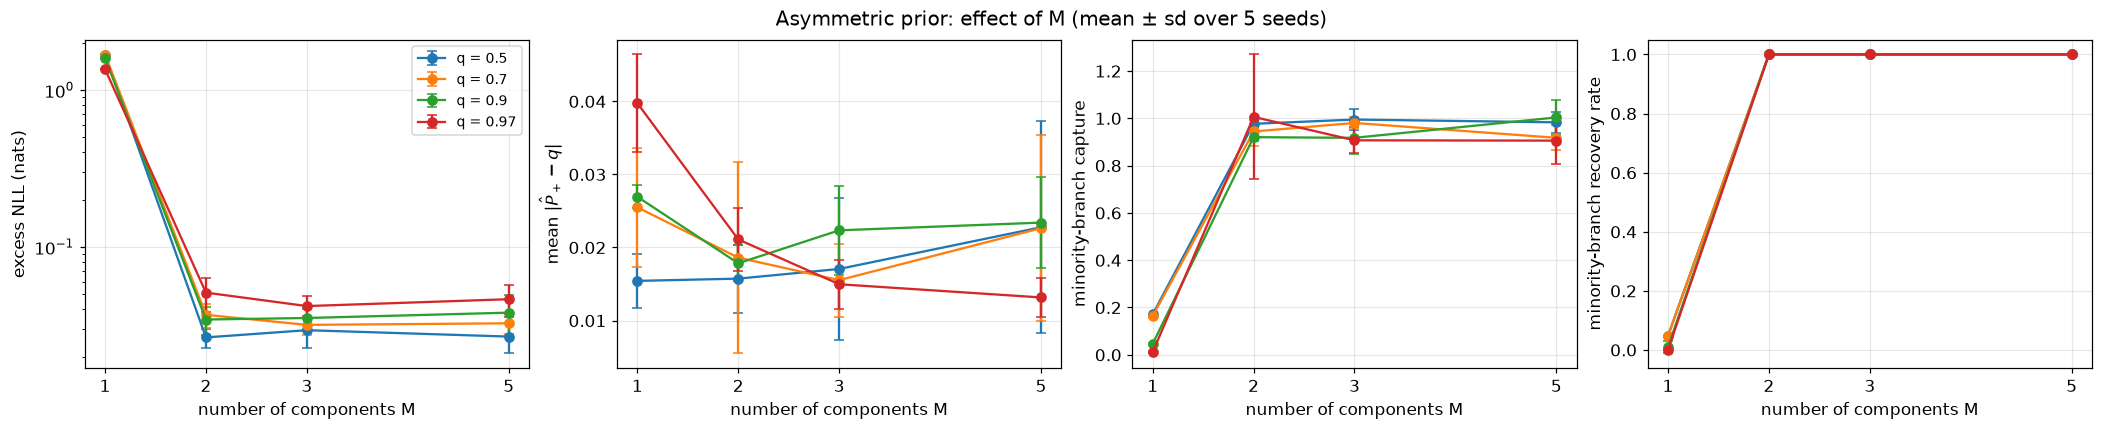

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, (col, lab) in zip(axes, [("excess_nll", "excess NLL (nats)"), ("branch_err", r"mean $|\hat P_+ - q|$"),
                                 ("capture_neg", "minority-branch capture"), ("recovered_neg", "minority-branch recovery rate")]):
    for q in Q_LIST:
        g = df_asym[df_asym.q == q].groupby("M")[col]
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", capsize=3, label=f"q = {q}")
    ax.set(xlabel="number of components M", ylabel=lab, xticks=M_LIST)
axes[0].set_yscale("log"); axes[0].legend()
fig.suptitle("Asymmetric prior: effect of M (mean ± sd over 5 seeds)")
savefig(fig, "07_asym_vs_M"); plt.show()

In [24]:
# ---- every individual run with the minority branch NOT reliably recovered (nothing is hidden) ----
fails = df_asym[(df_asym.M > 1) & (df_asym.recovered_neg < 0.9)]
print(f"MDN runs (M > 1) with minority-branch recovery rate < 0.9: {len(fails)} of {int((df_asym.M > 1).sum())}")
display(fails[["q", "M", "seed", "recovered_neg", "capture_neg", "excess_nll", "branch_err"]])
print("Per-seed results at the most extreme imbalance q = 0.97:")
display(df_asym[df_asym.q == 0.97].pivot(index="seed", columns="M", values="capture_neg").round(3))

MDN runs (M > 1) with minority-branch recovery rate < 0.9: 0 of 60


,q,M,seed,recovered_neg,capture_neg,excess_nll,branch_err


Per-seed results at the most extreme imbalance q = 0.97:


M,1,2,3,5
seed,,,,
0,0.020,0.745,0.890,0.913
1,0.007,1.407,0.976,0.897
2,0.009,1.125,0.826,1.029
3,0.010,0.911,0.909,0.754
4,0.010,0.842,0.933,0.935


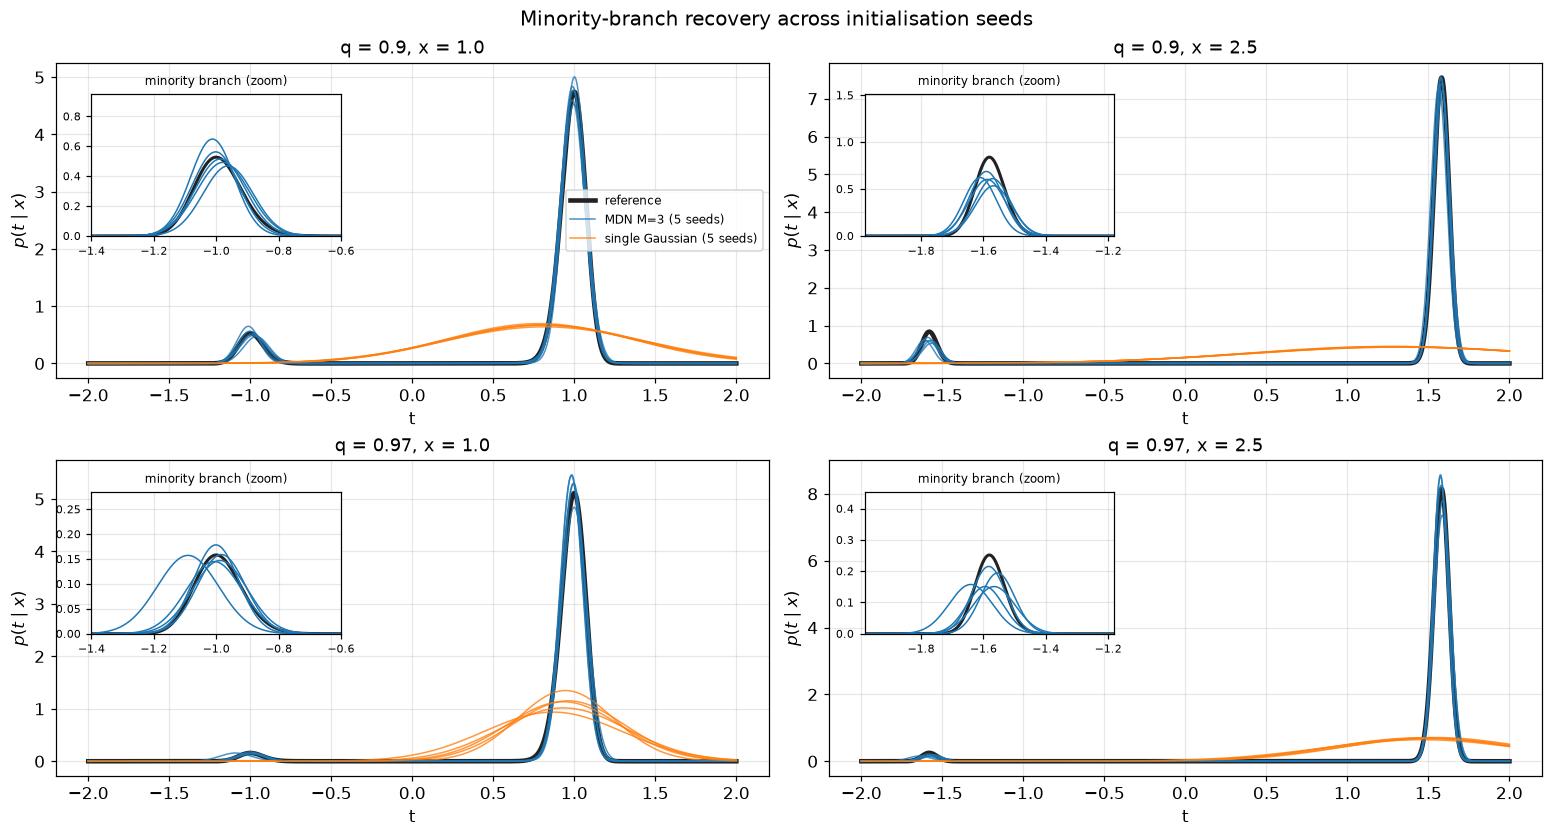

In [25]:
# ---- what the densities look like for every seed ----
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
for row, q in enumerate([0.9, 0.97]):
    dq = replace(BASE_DATA, q=q)
    for col, x in enumerate([1.0, 2.5]):
        ax = axes[row, col]
        ax.plot(T_GRID, R.reference_density_grid([x], T_GRID, A, SIGMA, q)[0], color=COLORS["reference"], lw=3, label="reference")
        for s in SEEDS:
            m3 = get_model(dq, TRAIN, MDNConfig(M=3), s, use_cache=True)
            m1 = get_model(dq, TRAIN, MDNConfig(M=1), s, use_cache=True)
            ax.plot(T_GRID, E.predict_conditional_density(m3, [x], T_GRID)[0], color=COLORS["mdn"], lw=1, alpha=0.8, label="MDN M=3 (5 seeds)" if s == 0 else None)
            ax.plot(T_GRID, E.predict_conditional_density(m1, [x], T_GRID)[0], color=COLORS["single"], lw=1, alpha=0.8, label="single Gaussian (5 seeds)" if s == 0 else None)
        ax.set(title=f"q = {q}, x = {x}", xlabel="t", ylabel=r"$p(t\mid x)$")
        ins = ax.inset_axes([0.05, 0.45, 0.35, 0.45])   # zoom on the minority branch
        ref_x = R.reference_density_grid([x], T_GRID, A, SIGMA, q)[0]
        ins.plot(T_GRID, ref_x, color=COLORS["reference"], lw=2)
        for s in SEEDS:
            m3 = get_model(dq, TRAIN, MDNConfig(M=3), s, use_cache=True)
            ins.plot(T_GRID, E.predict_conditional_density(m3, [x], T_GRID)[0], color=COLORS["mdn"], lw=1)
        ins.set_xlim(-np.sqrt(x) - 0.4, -np.sqrt(x) + 0.4)
        ins.set_ylim(0, 1.8 * ref_x[T_GRID < 0].max())   # y-scale set by the minority peak, not the majority one
        ins.set_title("minority branch (zoom)", fontsize=8); ins.tick_params(labelsize=7)
axes[0, 0].legend(loc="center right", fontsize=8)
fig.suptitle("Minority-branch recovery across initialisation seeds")
savefig(fig, "07_asym_densities_seeds"); plt.show()

**What the asymmetric-prior sweep shows.**
* **The single Gaussian ($M=1$) never recovers the minority branch.** Its minority capture falls from about 0.17 at $q=0.5$ to about 0.01 at $q=0.97$. It just moves its one bell toward the majority branch. This is a limitation of the model, not of training: every seed gives the same answer.
* **Every MDN with $M\ge2$ recovered the minority branch, at every $q$, for every seed** (0 of 60 runs below a recovery rate of 0.9). This includes $q=0.97$, where only about 3% of the training data, roughly 300 points, lie on the negative branch. In our setting we therefore did **not** observe the "missed branch" failure, even at a stronger imbalance than the suggested 90:10.
* Recovery is not perfect, though. Average minority capture drops from about 1.0 at $q=0.5$ to about 0.9 at $q\ge0.9$ (for $M=3$), so the rare branch tends to be slightly under-weighted. The spread across seeds also grows with imbalance. At $q=0.97$, individual runs range from 0.74 to 1.41 capture (the $M=2$ column of the per-seed table). The excess NLL creeps up with imbalance as well, from about 0.03 to 0.04–0.05 nats.
* **Effect of $M$:** going from 1 to 2 components makes all the difference. Going beyond 2 adds little, and $M=5$ does not hurt: the extra components simply get small weights.
* The branch-probability error of the MDNs stays around 0.015–0.025 at all imbalance levels.

The sign probability is learned well. What imbalance mainly affects is how accurately the *shape* of the rare branch is reproduced, and how much that varies between seeds.

### 7.2 Initialisation
Besides the 5 seeds, we compare two initialisation schemes for the component means: PyTorch's
**default** initialisation (all means start near 0) and a **spread** initialisation (means start
evenly spaced over $[-a,a]$, so one component begins on each side). The question is whether starting
a component on the rare side makes recovery more reliable.

In [26]:
df_init = run_sweep([(replace(BASE_DATA, q=q), MDNConfig(M=M, mu_init=init)) for q in [0.9, 0.97] for M in [2, 3]
                     for init in ["default", "spread"]], TRAIN, SEEDS, use_cache=USE_CACHE)
df_init.to_csv(RESULTS / "part5_initialisation.csv", index=False)
display(mean_sd_table(df_init, ["q", "M", "mu_init"], ["excess_nll", "capture_neg", "recovered_neg", "branch_err", "epochs_run"]))

  10/40 runs done


  20/40 runs done


  30/40 runs done


  40/40 runs done


excess_nll    capture_neg  recovered_neg     branch_err        epochs_run
q    M mu_init                                                                              
0.90 2 default  0.035 ± 0.007  0.920 ± 0.017  1.000 ± 0.000  0.018 ± 0.002  153.000 ± 29.757
       spread   0.042 ± 0.006  0.924 ± 0.072  1.000 ± 0.000  0.018 ± 0.005  119.600 ± 29.871
     3 default  0.035 ± 0.005  0.917 ± 0.069  1.000 ± 0.000  0.022 ± 0.006  101.800 ± 17.239
       spread   0.031 ± 0.006  0.885 ± 0.100  1.000 ± 0.000  0.016 ± 0.004   91.800 ± 20.897
0.97 2 default  0.051 ± 0.013  1.006 ± 0.264  1.000 ± 0.000  0.021 ± 0.004  144.000 ± 65.886
       spread   0.049 ± 0.006  1.002 ± 0.189  1.000 ± 0.000  0.018 ± 0.004  130.800 ± 26.119
     3 default  0.042 ± 0.007  0.907 ± 0.055  1.000 ± 0.000  0.015 ± 0.003  117.800 ± 53.261
       spread   0.047 ± 0.006  0.924 ± 0.092  1.000 ± 0.000  0.018 ± 0.005  106.200 ± 37.439

**Initialisation result.** Both schemes recovered the minority branch in every run. Their excess NLL
and capture differ by less than the seed-to-seed standard deviation, so neither scheme is clearly
better. Spread initialisation needed slightly fewer epochs on average, but the difference is also
within one standard deviation. With 10 000 training points the gradient from the rare branch is
strong enough that a component finds it even when all means start near 0. Initialisation mainly
changes *which* component ends up on which branch, not *whether* the branch is found.

### 7.3 Variance constraint
The floor $v_{\min}$ is the smallest variance a component may have. We vary it over five orders of
magnitude at $q=0.9$, $M=3$. For reference, the narrowest branch in the two-branch region has variance
$(\sigma/2a)^2\approx1.4\times10^{-3}$ (at $x=a^2$) and $(\sigma/2)^2\approx5.6\times10^{-3}$ at $x=1$.
A floor above these values forces components to be too wide.

  10/25 runs done


  20/25 runs done


  25/25 runs done


,excess_nll,w1,capture_neg,recovered_neg,branch_err,out_mass
var_floor,,,,,,
1.0000e-05,0.040 ± 0.013,0.029 ± 0.008,0.937 ± 0.056,1.000 ± 0.000,0.023 ± 0.006,0.008 ± 0.003
1.0000e-04,0.035 ± 0.005,0.032 ± 0.009,0.917 ± 0.069,1.000 ± 0.000,0.022 ± 0.006,0.007 ± 0.001
1.0000e-03,0.038 ± 0.011,0.030 ± 0.010,0.973 ± 0.097,1.000 ± 0.000,0.024 ± 0.011,0.009 ± 0.002
1.0000e-02,0.185 ± 0.003,0.040 ± 0.003,0.910 ± 0.059,1.000 ± 0.000,0.016 ± 0.005,0.020 ± 0.002
1.0000e-01,0.909 ± 0.001,0.168 ± 0.001,0.428 ± 0.010,0.324 ± 0.021,0.046 ± 0.001,0.062 ± 0.001


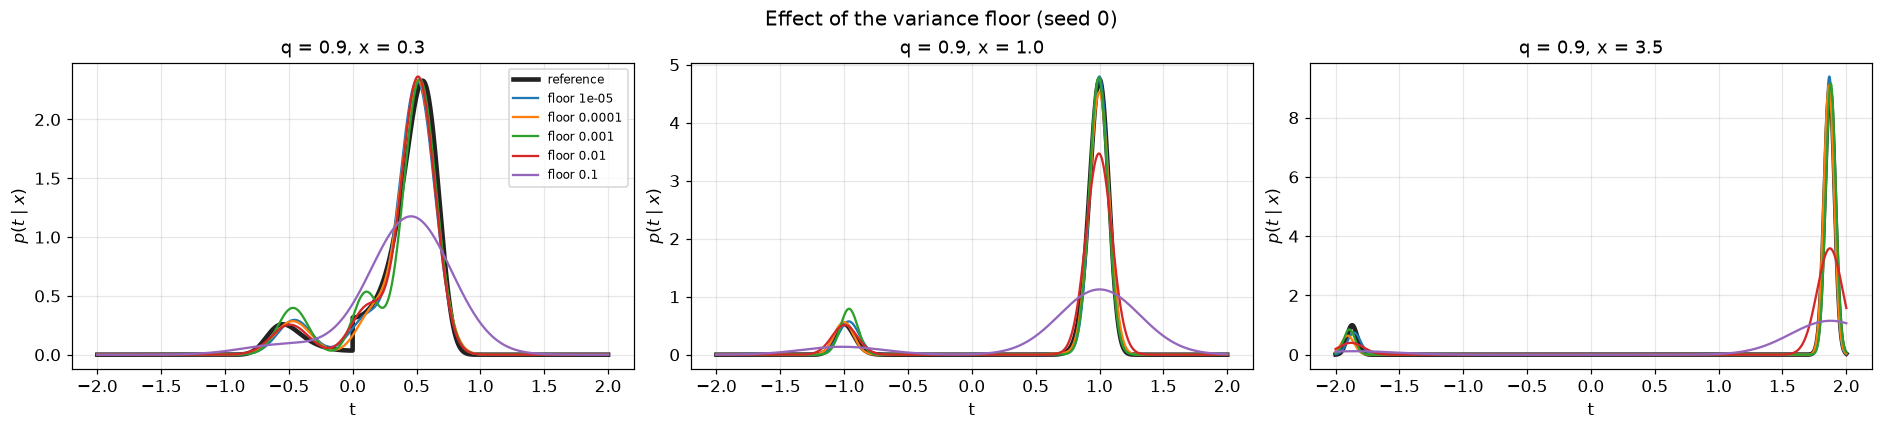

In [27]:
dq9 = replace(BASE_DATA, q=0.9)
df_floor = run_sweep([(dq9, MDNConfig(M=3, var_floor=v)) for v in FLOORS], TRAIN, SEEDS, use_cache=USE_CACHE)
df_floor.to_csv(RESULTS / "part5_variance_floor.csv", index=False)
display(mean_sd_table(df_floor, "var_floor", ["excess_nll", "w1", "capture_neg", "recovered_neg", "branch_err", "out_mass"]))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, x in zip(axes, [0.3, 1.0, 3.5]):
    ax.plot(T_GRID, R.reference_density_grid([x], T_GRID, A, SIGMA, 0.9)[0], color=COLORS["reference"], lw=3, label="reference")
    for v in FLOORS:
        mv = get_model(dq9, TRAIN, MDNConfig(M=3, var_floor=v), 0, use_cache=True)
        ax.plot(T_GRID, E.predict_conditional_density(mv, [x], T_GRID)[0], lw=1.5, label=f"floor {v:g}")
    ax.set(title=f"q = 0.9, x = {x}", xlabel="t", ylabel=r"$p(t\mid x)$")
axes[0].legend(fontsize=8)
fig.suptitle("Effect of the variance floor (seed 0)")
savefig(fig, "07_variance_floor"); plt.show()

**Variance-floor result.** This is the one setting in Part 5 where we saw a clear failure.
* Floors $10^{-5}$, $10^{-4}$ and $10^{-3}$ give statistically indistinguishable results. They all lie below the true branch variances. Even the smallest floor caused no collapse or instability in our runs, which we attribute to the large dataset, gradient clipping and early stopping.
* A floor of $10^{-2}$ (std 0.1) is **larger than the true branch variance** almost everywhere in the two-branch region. The components are forced to be too wide, the peaks become lower and broader (clearly visible at $x=3.5$), and the excess NLL rises about fivefold to 0.19. The branches are still found.
* A floor of $10^{-1}$ (std 0.32) **destroys the minority branch.** Each component is now as wide as the gap between the branches, the minority peak is smeared out (capture about 0.43, recovery rate about 0.32), and the excess NLL is about 0.9.

So the variance constraint has to be set below the narrowest feature the posterior actually has.
Here that is the branch width $\sigma/(2\sqrt{x})$, smallest at the boundary. Within that limit, its
exact value hardly matters.

### 7.4 Why MSE alone cannot assess recovery of a multimodal conditional distribution
For every MDN in the asymmetric sweep we compute the MSE of its *mean* prediction $\sum_j\pi_j\mu_j$.
If MSE were a useful diagnostic here, models that miss branches ($M=1$) would show a clearly worse MSE.

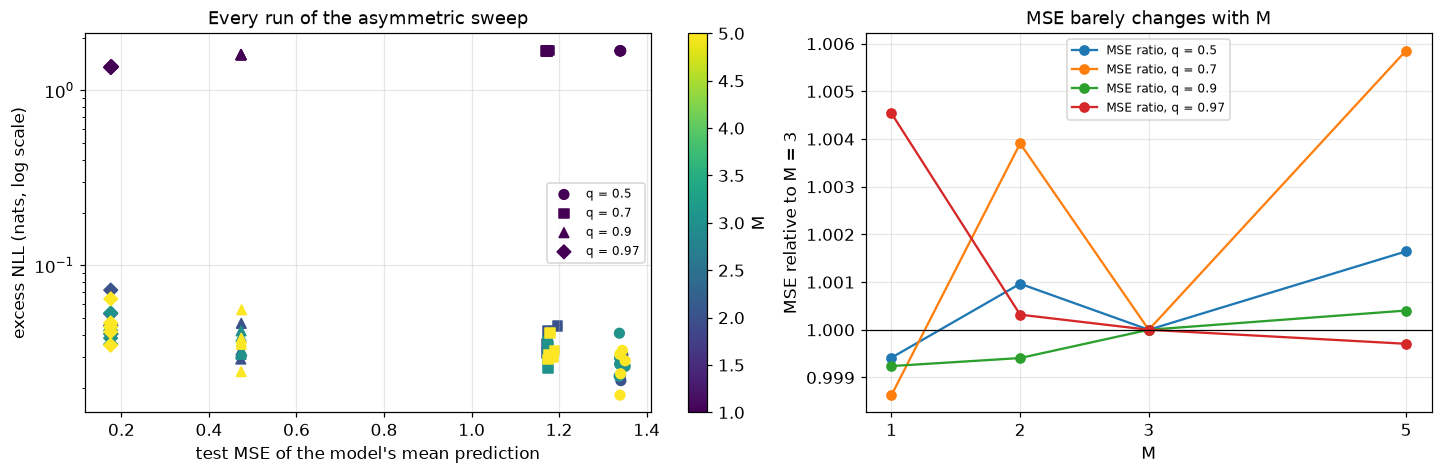

mse_of_mean                      excess_nll                      capture_neg                     
M              1      2      3      5          1      2      3      5           1      2      3      5
q                                                                                                     
0.50       1.340  1.342  1.341  1.343      1.678  0.027  0.030  0.027       0.171  0.977  0.995  0.983
0.70       1.173  1.179  1.174  1.181      1.681  0.037  0.032  0.033       0.164  0.944  0.980  0.918
0.90       0.473  0.473  0.474  0.474      1.594  0.035  0.035  0.038       0.046  0.920  0.917  1.004
0.97       0.176  0.176  0.175  0.175      1.357  0.051  0.042  0.046       0.011  1.006  0.907  0.906

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for q, mk in zip(Q_LIST, ["o", "s", "^", "D"]):
    d = df_asym[df_asym.q == q]
    sc = axes[0].scatter(d.mse_of_mean, d.excess_nll, c=d.M, cmap="viridis", marker=mk, s=40, label=f"q = {q}", vmin=1, vmax=5)
axes[0].set(xscale="linear", yscale="log", xlabel="test MSE of the model's mean prediction",
            ylabel="excess NLL (nats, log scale)", title="Every run of the asymmetric sweep")
fig.colorbar(sc, ax=axes[0], label="M"); axes[0].legend(fontsize=8)
for q in Q_LIST:
    g = df_asym[df_asym.q == q].groupby("M")
    axes[1].plot(M_LIST, g.mse_of_mean.mean() / g.mse_of_mean.mean().loc[3], marker="o", label=f"MSE ratio, q = {q}")
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set(xlabel="M", ylabel="MSE relative to M = 3", xticks=M_LIST, title="MSE barely changes with M")
axes[1].legend(fontsize=8)
savefig(fig, "07_mse_cannot_assess"); plt.show()
display(df_asym.groupby(["q", "M"])[["mse_of_mean", "excess_nll", "capture_neg"]].mean().unstack("M").round(3))

For each $q$, the models form a **vertical** band: MSE is almost identical across $M$ and seeds,
while the excess NLL differs by orders of magnitude. The single Gaussian ($M=1$), which cannot
represent the minority branch at all, has about the same MSE as an MDN that recovers both branches.
This is the theory from Part 2 at work. MSE scores only the conditional mean. Two very different
densities, one bimodal and one unimodal and wide, can share the same mean. It also scores only one
point, so it cannot tell whether probability mass sits on a branch or in the empty space between the
branches. To judge multimodal recovery you need distribution-level metrics: held-out NLL, a distance
to the reference density, and branch-level probability and mass checks.

## 8. Extension: quantitative branch recovery and noise robustness

### 8.1 Metric definitions (used throughout §6–§8)
**A. Branch-probability error.** $P_+(x)=\int_0^a p(t\mid x)\,dt$ (the reference, equal to $q$) and
$\hat P_+(x)=\int_0^\infty p_\theta(t\mid x)\,dt=\sum_j\pi_j(x)\,\Phi\!\big(\mu_j(x)/\sqrt{v_j(x)}\big)$ for the
MDN, computed exactly. $E_{\rm branch}=\frac1{n}\sum_{x}|\hat P_+(x)-P_+(x)|$, averaged over the first
**400 held-out test inputs** of each dataset. That set covers all four regions in proportion to how
often they occur.

**B. Branch-recovery check.** Only where the reference really has two separated modes: the 21
evenly spaced inputs $x\in[2\sigma,\,a^2-2\sigma]$. Below $2\sigma$ the modes merge, and near $a^2$
the boundary distorts them. Around each reference mode we take the neighbourhood
$N_\pm(x)=[\pm\sqrt x-w,\ \pm\sqrt x+w]$, $w=3\sigma/(2\sqrt{x})$ (three local posterior standard
deviations). Within this range these neighbourhoods are disjoint. *Capture*
$c_\pm(x)=\hat m(N_\pm)/m_{\rm ref}(N_\pm)$ is the predicted mass in the neighbourhood divided by the
reference mass there (1 = perfect). A branch is **recovered at $x$** if $c\ge0.5$, and the *recovery
rate* is the fraction of the 21 inputs where it is recovered. This uses probability mass, **not**
the number of mixture components.

**C. Wasserstein-1.** Both densities are evaluated on the common grid ($t\in[-2,2]$, 4001 points),
converted to probability weights (density × cell width, normalised to sum 1) and compared with
`scipy.stats.wasserstein_distance`. The MDN density is therefore **truncated to $[-a,a]$ and
renormalised** for this metric only. The mass it puts outside the support is reported separately as
`out_mass`. W1 is in units of $t$: it is the average distance probability mass has to be moved to
turn one density into the other.

Before using C we check that the grid is fine enough:

In [29]:
rows = []
for n in [1001, 4001, 16001]:
    g = np.linspace(-A, A, n)
    xe = base.x_eval[:200]
    w1 = E.evaluate_wasserstein(mdn_model, xe, g, A, SIGMA, 0.5).mean()
    br = E.evaluate_branch_metrics(mdn_model, base.x_rec, g, A, SIGMA, 0.5)
    rows.append(dict(grid_points=n, spacing=g[1] - g[0], mean_W1_MDN=w1, mean_capture_pos=br["capture_pos"].mean(),
                     mean_capture_neg=br["capture_neg"].mean()))
display(pd.DataFrame(rows))

,grid_points,spacing,mean_W1_MDN,mean_capture_pos,mean_capture_neg
0,1001,0.0040,0.0273,1.0018,0.9966
1,4001,0.0010,0.0273,1.0014,0.9962
2,16001,0.0003,0.0274,1.0013,0.9961


The metrics agree to about three significant figures between grids of 1001, 4001 and 16001
points, so the 4001-point grid is more than fine enough.

### 8.2 Observation-noise robustness
**Question.** How do NLL, branch-probability error, W1 and branch recovery change as the noise grows?
**Changed:** $\sigma\in\{0.05,0.15,0.30,0.50\}$, each with a freshly generated dataset (same seed and
sizes), for the symmetric ($q=0.5$) and imbalanced ($q=0.9$) priors.
**Fixed:** $a$, sample sizes, network, training protocol, variance floor $10^{-4}$.
**Models:** MDN ($M=3$) and single Gaussian ($M=1$), 5 seeds each.
The reference NLL changes with $\sigma$ (more noise means a wider true posterior), so we compare
models using the **excess** NLL. The recovery grid $[2\sigma, a^2-2\sigma]$ narrows as $\sigma$ grows,
so recovery is only scored where two branches really exist at that noise level.

In [30]:
noise_settings = [(replace(BASE_DATA, sigma=s, q=q), MDNConfig(M=M)) for s in SIGMAS for q in [0.5, 0.9] for M in [1, 3]]
df_noise = run_sweep(noise_settings, TRAIN, SEEDS, use_cache=USE_CACHE)
df_noise["ref_nll"] = [get_context(replace(BASE_DATA, sigma=s, q=q)).ref_nll for s, q in zip(df_noise.sigma, df_noise.q)]
df_noise.to_csv(RESULTS / "extension_noise_sweep.csv", index=False)
display(mean_sd_table(df_noise[df_noise.M == 3], ["q", "sigma"],
                      ["ref_nll", "test_nll", "excess_nll", "branch_err", "w1", "capture_neg", "recovered_neg", "out_mass"]))

  10/80 runs done


  20/80 runs done


  30/80 runs done


  40/80 runs done


  50/80 runs done


  60/80 runs done


  70/80 runs done


  80/80 runs done


ref_nll        test_nll     excess_nll     branch_err             w1    capture_neg  recovered_neg       out_mass
q   sigma                                                                                                                          
0.5 0.05   -1.412 ± 0.000  -1.361 ± 0.011  0.051 ± 0.011  0.026 ± 0.011  0.057 ± 0.032  0.975 ± 0.059  1.000 ± 0.000  0.005 ± 0.001
    0.15   -0.439 ± 0.000  -0.409 ± 0.007  0.030 ± 0.007  0.017 ± 0.010  0.040 ± 0.022  0.995 ± 0.045  1.000 ± 0.000  0.007 ± 0.001
    0.30    0.136 ± 0.000   0.160 ± 0.004  0.025 ± 0.004  0.024 ± 0.011  0.055 ± 0.020  0.979 ± 0.047  1.000 ± 0.000  0.009 ± 0.002
    0.50    0.526 ± 0.000   0.556 ± 0.005  0.030 ± 0.005  0.021 ± 0.009  0.048 ± 0.015  0.967 ± 0.020  1.000 ± 0.000  0.014 ± 0.001
0.9 0.05   -1.779 ± 0.000  -1.688 ± 0.007  0.091 ± 0.007  0.030 ± 0.011  0.038 ± 0.017  0.948 ± 0.142  1.000 ± 0.000  0.006 ± 0.002
    0.15   -0.806 ± 0.000  -0.770 ± 0.005  0.035 ± 0.005  0.022 ± 0.006  0.032 ± 0.009  0.917 ± 0.069  1.000 ± 0.000  0.007 ± 0.001
    0.30   -0.231 ± 0.000  -0.199 ± 0.003  0.032 ± 0.003  0.014 ± 0.005  0.029 ± 0.008  0.961 ± 0.073  1.000 ± 0.000  0.008 ± 0.003
    0.50    0.159 ± 0.000   0.187 ± 0.004  0.028 ± 0.004  0.015 ± 0.006  0.033 ± 0.007  0.898 ± 0.054  1.000 ± 0.000  0.008 ± 0.003

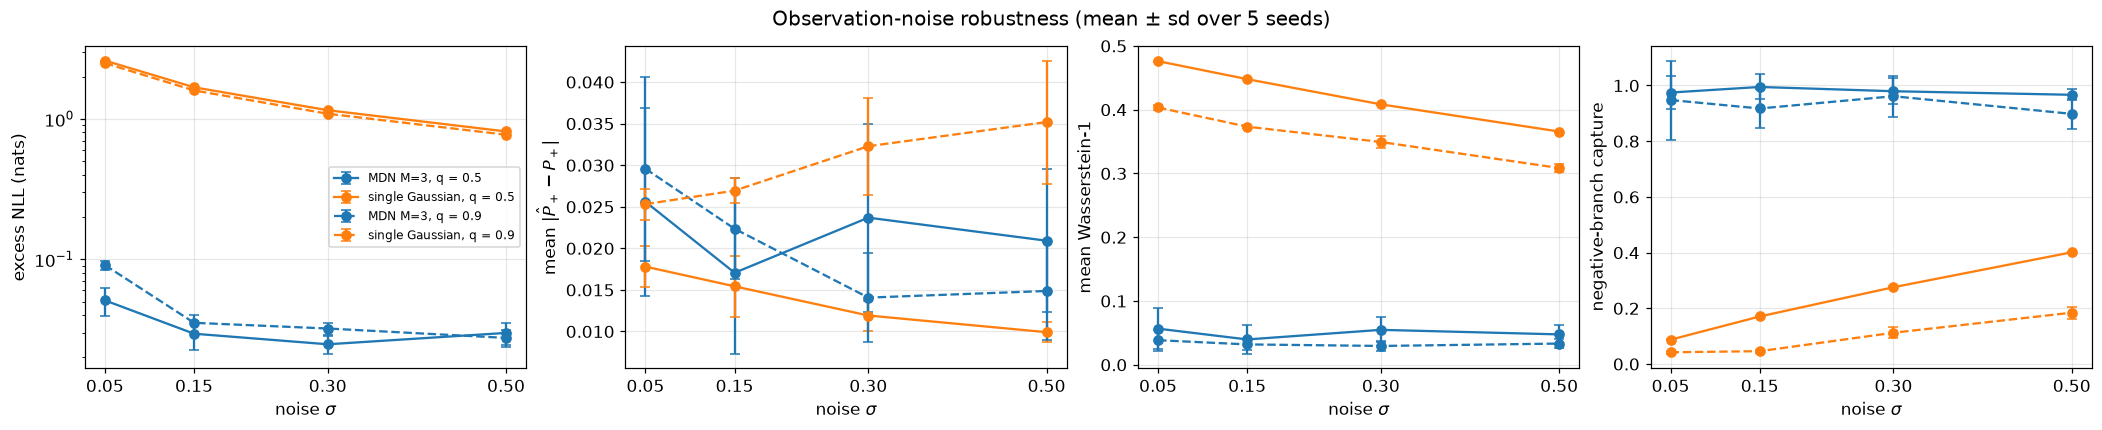

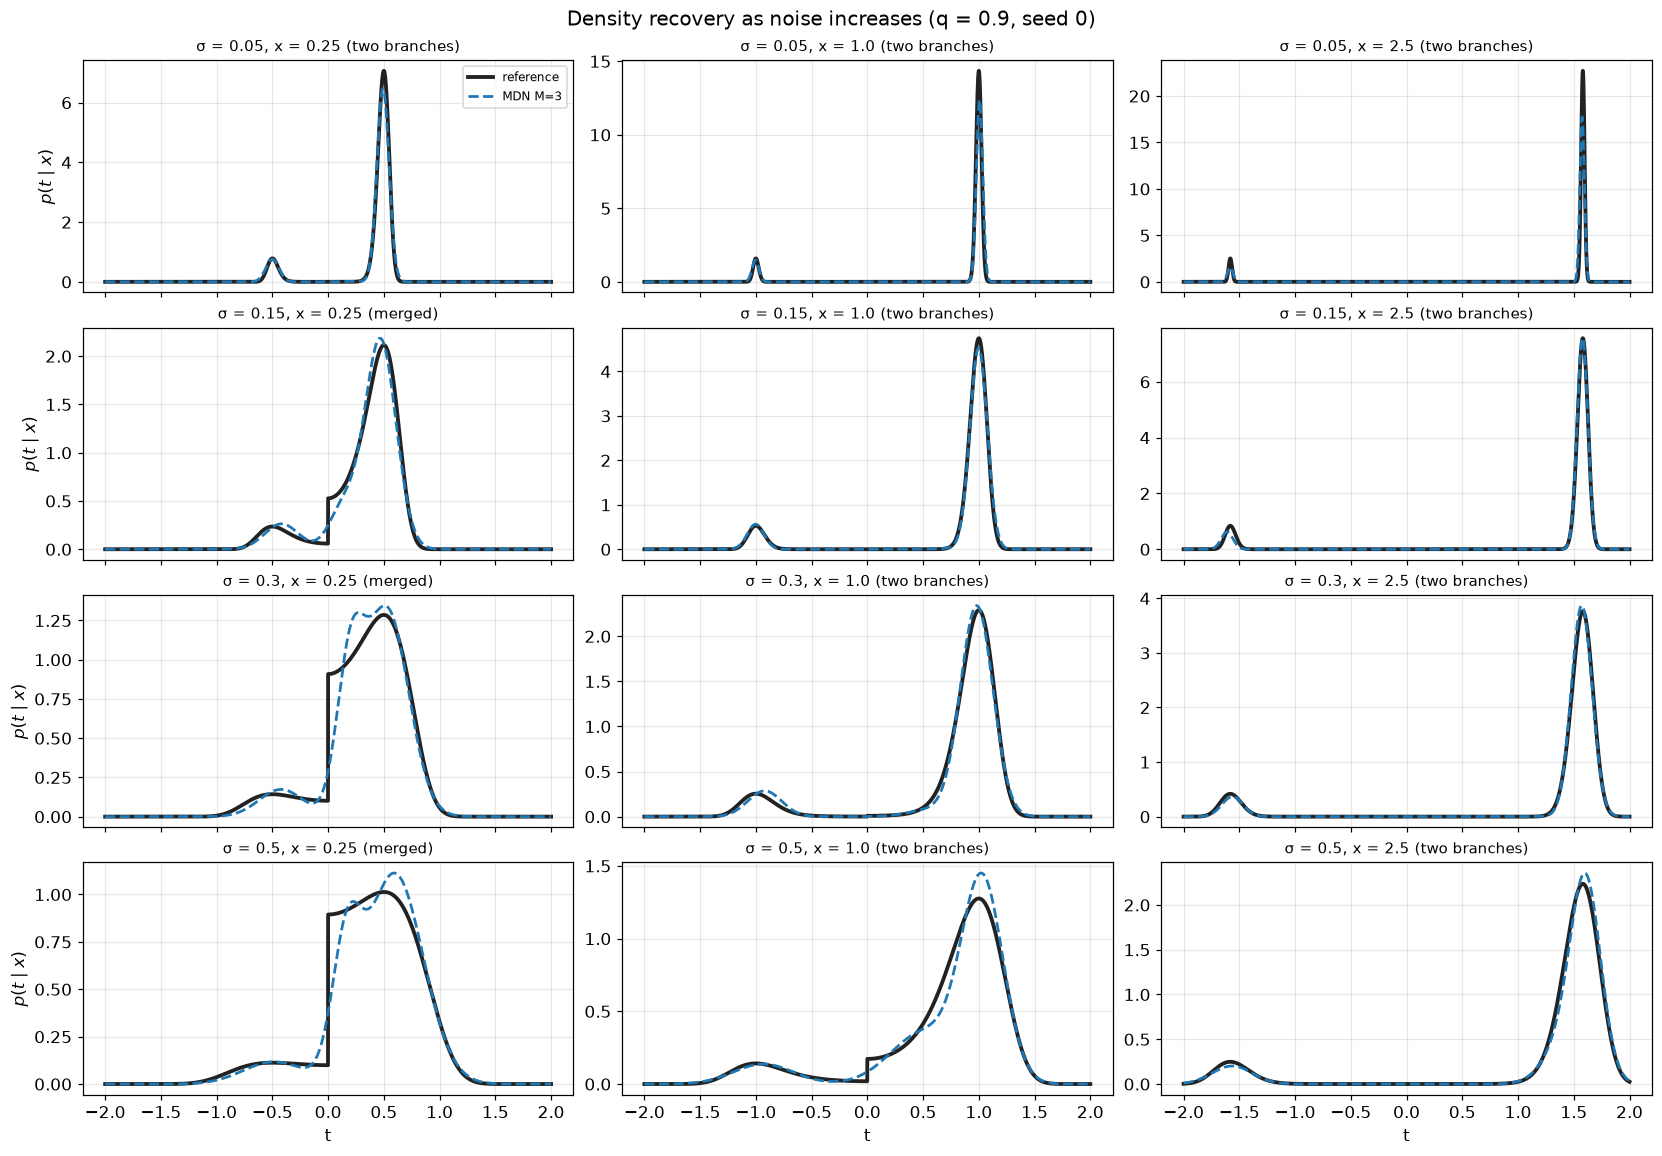

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, (col, lab) in zip(axes, [("excess_nll", "excess NLL (nats)"), ("branch_err", r"mean $|\hat P_+ - P_+|$"),
                                 ("w1", "mean Wasserstein-1"), ("capture_neg", "negative-branch capture")]):
    for q, ls in [(0.5, "-"), (0.9, "--")]:
        for M, c in [(3, COLORS["mdn"]), (1, COLORS["single"])]:
            g = df_noise[(df_noise.q == q) & (df_noise.M == M)].groupby("sigma")[col]
            ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), color=c, ls=ls, marker="o", capsize=3,
                        label=f"{'MDN M=3' if M == 3 else 'single Gaussian'}, q = {q}")
    ax.set(xlabel=r"noise $\sigma$", ylabel=lab, xticks=SIGMAS)
axes[0].set_yscale("log"); axes[0].legend(fontsize=8)
fig.suptitle("Observation-noise robustness (mean ± sd over 5 seeds)")
savefig(fig, "08_noise_metrics"); plt.show()

fig, axes = plt.subplots(len(SIGMAS), 3, figsize=(15, 2.6 * len(SIGMAS)), sharex=True)
for i, s in enumerate(SIGMAS):
    d = replace(BASE_DATA, sigma=s, q=0.9)
    m3 = get_model(d, TRAIN, MDNConfig(M=3), 0, use_cache=True)
    for j, x in enumerate([0.25, 1.0, 2.5]):
        ax = axes[i, j]
        ax.plot(T_GRID, R.reference_density_grid([x], T_GRID, A, s, 0.9)[0], color=COLORS["reference"], lw=2.5, label="reference")
        ax.plot(T_GRID, E.predict_conditional_density(m3, [x], T_GRID)[0], color=COLORS["mdn"], lw=1.8, ls="--", label="MDN M=3")
        ax.set_title(f"σ = {s}, x = {x} ({R.classify_region(x, A, s)})", fontsize=10)
        if j == 0: ax.set_ylabel(r"$p(t\mid x)$")
for ax in axes[-1]: ax.set_xlabel("t")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Density recovery as noise increases (q = 0.9, seed 0)")
savefig(fig, "08_noise_densities"); plt.show()

**What the noise sweep shows.** We did not assume a direction in advance, and the results are not
uniformly "more noise is worse":
* **The MDN's excess NLL is highest at the *smallest* noise.** At $\sigma=0.05$ it is about 0.05 ($q=0.5$) and 0.09 ($q=0.9$), against about 0.025–0.035 for $\sigma\ge0.15$. With little noise the branches are extremely narrow (std $\sigma/(2\sqrt x)$, down to about 0.006), and the MDN underestimates the peak heights (top row of the density figure). A small error in the width or location of a very sharp peak costs a lot of log-likelihood.
* **W1 and the branch-probability error show no clear trend with $\sigma$.** They stay around 0.03–0.06 and 0.014–0.030 for the MDN. W1 measures *how far* mass is misplaced, and the misplacement stays small in $t$ units even when the NLL penalty is large.
* **Branch recovery stays at 100% at every noise level, for both priors** (scored only on $[2\sigma, a^2-2\sigma]$, where two branches exist). Minority capture stays between about 0.90 and 0.98.
* **The single Gaussian gets *relatively* better as noise grows.** Its excess NLL falls from about 2.5–2.6 at $\sigma=0.05$ to about 0.8 at $\sigma=0.5$, and its capture rises. This is not because it learns the branches: more noise widens and blurs the true posterior, so one wide bell is a less terrible approximation. It is still about 25 times worse than the MDN in excess NLL at $\sigma=0.5$.
* **A new feature appears at large noise:** for $q=0.9$ the reference posterior has a visible **jump at $t=0$**, inherited from the jump in the piecewise prior. When the noise blurs the branches together, mass near $t=0$ is weighted by $2q$ on one side and $2(1-q)$ on the other. A mixture of Gaussians can only approximate this step with a smooth ramp (bottom rows of the figure). This is another case where the exact posterior has structure, a discontinuity or a hard edge, that a Gaussian mixture cannot represent exactly.

**Answer to the extension question.** In our experiments, with 10 000 training points, the MDN
recovered both inverse branches reliably across all imbalance levels (up to 97:3) and all noise
levels (0.05–0.5). What gets worse is the *precision* of the recovered density. It degrades most
when the posterior has very sharp features (low noise), hard edges (the support boundary and the
prior jump), or a very rare branch, where the seed-to-seed variability is largest. Recovery only
broke down when the model was too constrained: one component, or a variance floor wider than the
branches.

## 9. Summary of results

The cell below collects the key numbers from the experiments above (all computed in this run).

In [32]:
def ms(d, col):
    return f"{d[col].mean():.3f} ± {d[col].std():.3f}"

summary = []
b = df_base
summary.append(("Part 4", "baseline excess NLL, single Gaussian (M=1)", ms(b[b.M == 1], "excess_nll")))
summary.append(("Part 4", "baseline excess NLL, MDN (M=3)", ms(b[b.M == 3], "excess_nll")))
summary.append(("Part 4", "baseline W1, single Gaussian / MDN M=3", f"{ms(b[b.M == 1], 'w1')} / {ms(b[b.M == 3], 'w1')}"))
summary.append(("Part 4", "residual sd (true t / MDN / single Gauss. / MSE), sigma = 0.15",
                " / ".join(f"{res[k].std():.3f}" for k in ["true t (= noise eps)", "MDN sample", "single-Gaussian sample", "MSE point prediction"])))
for q in Q_LIST:
    d = df_asym[(df_asym.q == q) & (df_asym.M == 3)]
    summary.append(("Part 5", f"q = {q}: MDN M=3 minority capture / recovery rate", f"{ms(d, 'capture_neg')} / {ms(d, 'recovered_neg')}"))
summary.append(("Part 5", "MDN runs (M>1) with minority recovery < 0.9", f"{len(fails)} of {int((df_asym.M > 1).sum())}"))
for v in [FLOORS[0], FLOORS[-1]]:
    d = df_floor[df_floor.var_floor == v]
    summary.append(("Part 5", f"q = 0.9, floor {v:g}: excess NLL / minority capture", f"{ms(d, 'excess_nll')} / {ms(d, 'capture_neg')}"))
for s in SIGMAS:
    d = df_noise[(df_noise.sigma == s) & (df_noise.q == 0.9) & (df_noise.M == 3)]
    summary.append(("Extension", f"sigma = {s}, q = 0.9, MDN M=3: excess NLL / W1 / minority capture",
                    f"{ms(d, 'excess_nll')} / {ms(d, 'w1')} / {ms(d, 'capture_neg')}"))
summary_df = pd.DataFrame(summary, columns=["part", "quantity", "value (mean ± sd over seeds)"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
with pd.option_context("display.max_colwidth", 200):
    display(summary_df)

,part,quantity,value (mean ± sd over seeds)
0,Part 4,"baseline excess NLL, single Gaussian (M=1)",1.678 ± 0.000
1,Part 4,"baseline excess NLL, MDN (M=3)",0.030 ± 0.007
2,Part 4,"baseline W1, single Gaussian / MDN M=3",0.448 ± 0.000 / 0.040 ± 0.022
3,Part 4,"residual sd (true t / MDN / single Gauss. / MSE), sigma = 0.15",0.151 / 0.161 / 2.626 / 1.198
4,Part 5,q = 0.5: MDN M=3 minority capture / recovery rate,0.995 ± 0.045 / 1.000 ± 0.000
5,Part 5,q = 0.7: MDN M=3 minority capture / recovery rate,0.980 ± 0.024 / 1.000 ± 0.000
6,Part 5,q = 0.9: MDN M=3 minority capture / recovery rate,0.917 ± 0.069 / 1.000 ± 0.000
7,Part 5,q = 0.97: MDN M=3 minority capture / recovery rate,0.907 ± 0.055 / 1.000 ± 0.000
8,Part 5,MDN runs (M>1) with minority recovery < 0.9,0 of 60
9,Part 5,"q = 0.9, floor 1e-05: excess NLL / minority capture",0.040 ± 0.013 / 0.937 ± 0.056


## 10. Conclusions

**Part 1: the exact posterior.** $p(t\mid x)\propto\exp[-(x-t^2)^2/2\sigma^2]$ on $[-a,a]$, normalised by
one-dimensional quadrature. The quadrature reference passed every check: it integrates to 1, it is
symmetric, $P(t>0\mid x)=q$, its value is insensitive to tolerance and grid, and its modes agree with
the analysis. The input space splits into four regions: **no real inverse** ($x\le0$, one mode at 0),
**merged branches** ($0<x\lesssim2\sigma$), **two distinct branches** at $\pm\sqrt x$
($2\sigma\le x\le a^2$), and **beyond the support** ($x>a^2$, modes stuck at $\pm a$).

**Part 2: the MSE network** estimates the conditional mean $\mathbb E[t\mid x]$. Our trained network
matches the quadrature mean, and its test MSE equals that of the exact conditional mean. It is
therefore an accurate estimate of the wrong summary for this problem. Under the symmetric prior its
prediction lies *between* the branches for every $x$ in the two-branch region. With $q=0.9$ it lies
near the majority branch only for $x\lesssim1.1$ and between the branches beyond that. It never
represents the second solution. Switching to absolute error (§4.1) learns the conditional median
instead: with $q=0.9$ it sits on the majority branch, a valid but incomplete answer, and with the
symmetric prior it is only weakly determined anywhere in the gap. Either way one answer comes out.

**Part 3: the MDN** (softmax weights, softplus-plus-floor variances, log-sum-exp likelihood) trained
stably. Its weights sum to one, its variances stay positive, and its likelihood is finite even for
extreme inputs, where a naive implementation returns $-\infty$. Its components lock onto $\pm\sqrt x$,
with variances that follow the theoretical branch width.

**Part 4: comparison.** On the same held-out test set, the MDN's NLL is within about 0.03 nats of the
exact posterior's, while the single-Gaussian network is about 1.7 nats worse. W1 tells the same
story (about 0.03–0.04 vs 0.45). Branch probabilities are close to 0.5 for *both* models, which shows
that a correct sign split does not imply a correct density. Forward residuals of MDN samples have
about the spread of the noise ($\sigma=0.15$). Residuals of single-Gaussian samples and of the MSE
prediction are an order of magnitude larger. The residuals are *meant* to be non-zero, because the
data is noisy.

**Part 5: imbalance and sensitivity.** With $M\ge2$, the MDN recovered the minority branch in every
run we trained, at 70:30, 90:10 and even 97:3. The rare branch was, however, slightly under-weighted
(capture about 0.9), and its shape varied more across seeds as imbalance grew. The decisive factors
were **model capacity** (one component can never represent both branches, whatever the data) and
the **variance constraint** (a floor wider than the branch width smears the rare branch away).
Initialisation scheme and $M\ge2$ had only minor effects. MSE was essentially identical for models
that do and do not represent both branches, so **MSE cannot assess multimodal recovery**. It only
sees the conditional mean.

**Extension.** Recovery of both branches was robust to observation noise between 0.05 and 0.5. Density
accuracy in NLL terms was worst at the *lowest* noise, where the posterior peaks are sharpest. The
single Gaussian looked relatively less bad at high noise only because the true posterior itself
becomes blurrier.

**Limitations.**
* All results use one dataset size (10 000 training points) and one network size. With much less data, or more extreme imbalance, the rare branch might well be missed. We did not test this.
* A Gaussian mixture cannot represent the hard support edges or the prior's jump at $t=0$ exactly. Our grid metrics truncate the MDN to $[-a,a]$, and we report the leaked mass separately (about 1% for the MDN).
* The branch-recovery threshold (capture $\ge0.5$ inside a 3-standard-deviation neighbourhood) is our own definition. It is fairly lenient, which is why we also report the raw capture values.
* GPU training is not bit-for-bit deterministic, so retraining without the cache can change the last digits of some metrics.

**Bottom line.** The point is not simply "MDN beats MSE". MSE answers a different question: it
returns the average of the valid solutions, which is usually not a valid solution itself. A
conditional density model answers the right question. With adequate capacity and a sensible
variance constraint, it recovers every inverse branch, including rare ones, across a range of noise
levels. The remaining errors sit where the true posterior has features a Gaussian mixture cannot
draw exactly: very sharp peaks, hard edges and the prior's jump at $t=0$.